# CS3807 – Deep Learning Laboratory | Experiments 8 & 9
## Effect of Attention Type and Attention Position in a Pretrained ResNet50
### 🍎 Apple-silicon edition: runs on the MacBook (M4) GPU through TensorFlow-Metal

**Shiv Nadar University Chennai** · B.Tech Artificial Intelligence & Data Science · Semester V · AY 2026–27

This notebook implements **every task in the lab sheet**, in the same order as the PDF. Each code section is preceded by a short explanation of *what* we are doing and *why*, so you can learn while you run it.

### Map: notebook sections ↔ lab-sheet sections

| Notebook part | Lab-sheet sections |
|---|---|
| 0. Prerequisites | (background you need before §1) |
| 1. Objective & learning outcomes | §1, §2 |
| 2. Setup | – |
| 3. Dataset, preprocessing, split | §3 |
| 4. ResNet50 and its feature hierarchy | §4, §5 |
| 5. Why position matters + candidate positions | §6, §7 |
| 6. Attention modules (channel, spatial, CS, self, SE, ECA, CBAM, Coordinate) | §9 – §12, §19 |
| 7. Inserting attention, transfer learning, loss, metrics, protocol, baseline | §8, §13, §20 – §22, §34 |
| 8. Experiments 1 – 5 (type, position, multi-position, order, kernel) | §14 – §18, §35 |
| 9. Additional mechanisms | §19, §36 |
| 10. Required main result table | §23 |
| 11. Graphical analysis | §24 |
| 12. Confusion matrices | §25 |
| 13. Qualitative analysis: Grad-CAM, internal maps, position maps, comparisons | §26 – §32 |
| 14. Analysis, 35 questions, observations, report skeleton | §33, §37 – §41 |

---
# Part 0 · Prerequisites (read this first)

## 0.1 Concepts you should be comfortable with

| Concept | One-line meaning | Why it matters here |
|---|---|---|
| **Convolution / feature map** | A learned filter slides over an image and produces a grid of responses. | Attention modules operate on feature maps of shape `H × W × C`. |
| **Pooling, stride** | Down-sampling that shrinks `H × W`. | Explains why resolution falls with depth in ResNet50. |
| **BatchNorm, ReLU** | Normalisation and non-linearity inside every ResNet block. | Frozen BatchNorm matters during fine-tuning. |
| **Residual (skip) connection** | `y = F(x) + x`. The block learns a *correction* to its input. | Makes 50-layer networks trainable. |
| **Transfer learning** | Re-use weights learned on ImageNet, train a small new head. | Our only backbone is ImageNet-pretrained ResNet50. |
| **Global Average Pooling (GAP)** | Average each channel over `H × W` → one number per channel. | Used in the classifier head *and* in channel attention. |
| **Softmax + categorical cross-entropy** | Turns scores into class probabilities; penalises low probability on the true class. | The loss for all experiments. |
| **Precision / Recall / F1 / confusion matrix** | Per-class quality measures. | Macro-F1 exposes class imbalance that accuracy hides. |
| **Matrix multiplication & softmax over rows** | `softmax(QKᵀ/√d)V`. | Core of self-attention. |
| **Gradients (autograd)** | `∂ score / ∂ activation`. | Grad-CAM uses gradients of the class score. |
| **Ablation study** | Change *one* factor, keep everything else fixed. | The entire lab is a set of controlled ablations. |

## 0.2 Software & hardware (this edition: Mac with an Apple M-series chip, e.g. M4)
* Training runs on the **Apple GPU** through TensorFlow's Metal plugin (`tensorflow-metal`). The plugin only works with one exact set of versions: **Python 3.12 · TensorFlow 2.18.1 · tensorflow-metal 1.2.0 · Keras 3.8.0** (newer TensorFlow or Python 3.13 break it). The setup steps are in the next cell.
* Also needed: `scikit-learn`, `pandas`, `matplotlib`, `jinja2` (table styling) and `ipykernel` (so VS Code / Jupyter can run the notebook). `tensorflow-datasets` is **not** needed: the flowers are downloaded directly.
* Time: the **speed test** in Part 7 measures your Mac and prints the estimated minutes per experiment and the total. The full study is **18 trained models**; the minimum mandatory set (§35) is 7. Use `QUICK_MODE=True` first to test the whole pipeline.
* Results are **saved to disk after each experiment** and finished experiments are **skipped** when you run again, so you can stop and continue later (an interrupted experiment restarts from epoch 1).

## 0.3 Shape cheat-sheet for ResNet50 (input 224×224×3)

| Position | Location | `H × W` | `C` | `N = H·W` | `N²` (self-attention matrix) |
|---|---|---|---|---|---|
| P1 | after conv2_x | 56 × 56 | 256 | 3136 | 9.8 M |
| P2 | after conv3_x | 28 × 28 | 512 | 784 | 614 k |
| P3 | after conv4_x | 14 × 14 | 1024 | 196 | 38 k |
| P4 | after conv5_x | 7 × 7 | 2048 | 49 | 2.4 k |

Deeper ⇒ **fewer pixels, more channels, more semantic**.

## 0.4 How to work through the notebook
1. Run cells top to bottom. Read the markdown before each code cell.
2. Do the **“✍️ Your analysis”** cells yourself, in your own words, from *your* numbers. The lab sheet explicitly says conclusions must come from your results, not from assumptions.
3. Look at **several** images before drawing a qualitative conclusion (the sheet forbids single-image conclusions).
4. Note: with ~551 test images, differences of ~1–1.5 % accuracy are within statistical noise. The notebook prints this so you do not over-interpret tiny gaps.

---
# Part 1 · Objective & Learning Outcomes (§1, §2)

**Objective.** Understand how different attention mechanisms modify a pretrained CNN and how the **position** where attention is inserted influences image-classification performance, using a single backbone: **ResNet50 pretrained on ImageNet**.

**You will investigate:** channel attention · spatial attention · sequential channel–spatial attention · lightweight self-attention · insertion positions · single- vs multi-stage attention · attention ordering · additional established mechanisms (SE, ECA, CBAM, Coordinate) · internal attention maps vs Grad-CAM.

**Key message:** *attention effectiveness = type + position + feature resolution + feature semantics + model complexity.*

**Learning outcomes (16).** After this lab you should be able to: explain the stage-wise ResNet50 architecture; distinguish early/intermediate/late features; explain the motivation for attention; implement channel, spatial, channel–spatial and self-attention; insert attention at different stages of a pretrained network; analyse the influence of position; compare mechanisms under a controlled protocol; analyse accuracy and class-wise performance; visualise internal attention maps; generate Grad-CAM; distinguish internal attention from post-hoc explanation; analyse accuracy–complexity trade-offs; and perform controlled ablations.

---
# Part 2 · Setup

## 🍎 How to run this on your Mac (Apple silicon, M4)

**What is different from the Colab version:** no Google Drive and no per-epoch checkpoints; everything is saved in a folder `lab_outputs_mac/` next to this notebook. The flowers dataset is downloaded directly (same images as `tf_flowers`). Training uses the Apple GPU via `tensorflow-metal`, XLA is switched off (Metal does not support it), the input pipeline and augmentation run on the CPU while the model runs on the GPU, and GPU memory is freed between experiments. A GPU self-test (Part 2) and a speed test (Part 7) were added.

### One-time setup (Terminal)
```bash
cd ~/path/to/the/folder/with/this/notebook          # ← your folder
/opt/homebrew/bin/python3.12 -m venv .venv          # Python 3.12 is required (3.13 does not work with tensorflow-metal)
source .venv/bin/activate
python -m pip install --upgrade pip
pip install "tensorflow==2.18.1" "tensorflow-metal==1.2.0" "keras==3.8.0" scikit-learn pandas matplotlib jinja2 ipykernel
python -c "import tensorflow as tf; print(tf.config.list_physical_devices('GPU'))"   # must print one GPU device
```
No `python3.12`? Install it with `brew install python@3.12`.

### Run
1. In VS Code: *File → Open Folder…* (the folder above), open this notebook, click **Select Kernel** (top right) → *Python Environments* → **.venv (Python 3.12)**.
2. Run the cells **from the top, in order**. The environment check and the GPU self-test (Part 2) must both show ✅.
3. Part 7 has a **speed test** that prints how long one experiment and the whole study will take on your Mac.
4. First time (recommended): set `QUICK_MODE = True` in the configuration cell and run down to Part 8's first training cell until the first model prints a `✔ … test acc=…` line (2+2 epochs, a few minutes); stop the cell (■). Then set `QUICK_MODE = False`, **Restart** the kernel and **Run All**. Quick-mode results are kept in a separate sub-folder and never mix with the real ones.
5. Keep the Mac awake and plugged in during training: in a separate Terminal window run `caffeinate -dis` (stop it with Ctrl+C afterwards) and don't close the lid.
6. If the kernel dies or you stop it: restart the kernel and run from the top again. Finished experiments are skipped; only the interrupted one starts again.

### Troubleshooting
* `NotFoundError … libmetal_plugin.dylib` on `import tensorflow` → wrong versions. Run `pip install --force-reinstall "tensorflow==2.18.1" "tensorflow-metal==1.2.0" "keras==3.8.0"` inside the `.venv`.
* No GPU listed → the notebook is not using the `.venv` kernel, or Python is the Intel build (`python -c "import platform; print(platform.machine())"` must print `arm64`).
* "Running cells … requires the ipykernel package" → you picked a different Python; select the `.venv` kernel.
* Kernel crashes with memory errors → close other heavy apps. As a last resort set `BATCH_SIZE = 16` (then **all** experiments must be re-run with it, §34).
* GPU self-test shows ⚠️ or training gives NaN → `pip uninstall tensorflow-metal` makes everything run on the CPU (correct, but many times slower).

In [2]:
# Environment check - installs nothing (see the setup steps above). Run it first.
import sys, platform
from importlib.metadata import version, PackageNotFoundError
print("Python", sys.version.split()[0], "|", platform.platform(), "|", platform.machine(), "\n")
problems = []
if platform.system() != "Darwin" or platform.machine() != "arm64":
    problems.append("this edition is for Apple-silicon Macs (arm64); x86_64 means an Intel/Rosetta Python - use /opt/homebrew/bin/python3.12")
if sys.version_info[:2] != (3, 12):
    problems.append(f"Python {sys.version_info[0]}.{sys.version_info[1]} - tensorflow-metal needs Python 3.12: select the .venv kernel")
for pkg, want in {"tensorflow": "2.18.1", "tensorflow-metal": "1.2.0", "keras": "3.8.0"}.items():
    try: have = version(pkg)
    except PackageNotFoundError: have = None
    print(f"{pkg:17s} {have or 'NOT INSTALLED':14s} (expected {want})")
    if have != want: problems.append(f"{pkg}: expected {want}, found {have}")
for pkg in ["scikit-learn", "pandas", "matplotlib", "jinja2", "ipykernel"]:
    try: print(f"{pkg:17s} {version(pkg)}")
    except PackageNotFoundError: problems.append(f"{pkg} is not installed")
print("\n✅ environment looks right" if not problems else "\n⚠️  Fix these first:\n - " + "\n - ".join(problems))

Python 3.12.13 | macOS-26.6.2-arm64-arm-64bit | arm64 

tensorflow        2.18.1         (expected 2.18.1)
tensorflow-metal  1.2.0          (expected 1.2.0)
keras             3.8.0          (expected 3.8.0)
scikit-learn      1.9.1
pandas            3.0.6
matplotlib        3.11.2
jinja2            3.1.6
ipykernel         7.4.0

✅ environment looks right


In [6]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"            # Keras 3 runs on TensorFlow (-> Metal GPU)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")    # hide TensorFlow's C++ info messages
import json, time, math, random, gc, itertools, warnings, hashlib, shutil, glob, tarfile, urllib.request, ssl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import setuptools
import tensorflow as tf
import keras
from keras import layers
from keras.applications.resnet50 import preprocess_input
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)
warnings.filterwarnings("ignore")
tf.config.set_soft_device_placement(True)   # an op without a Metal kernel quietly runs on the CPU instead of failing

GPUS = tf.config.list_physical_devices("GPU")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| backend:", keras.backend.backend())
print("GPUs:", GPUS)
print("✅ Apple GPU found - training will run on it." if GPUS else
      "⚠️  No GPU visible - everything will run on the CPU (very slow). See Troubleshooting in the setup cell.")

TensorFlow 2.18.1 | Keras 3.8.0 | backend: tensorflow
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ Apple GPU found - training will run on it.


### GPU self-test (a few seconds)
The same matrix multiplication, convolution and softmax are computed on the Apple GPU and on the CPU; the results must agree. It also measures the raw GPU speed.

In [7]:
def metal_self_test():
    if not GPUS:
        print("no GPU -> skipped"); return
    rng = np.random.default_rng(0)
    a, b = rng.standard_normal((1024, 1024), dtype=np.float32), rng.standard_normal((1024, 1024), dtype=np.float32)
    x = rng.standard_normal((8, 56, 56, 64), dtype=np.float32)
    k = 0.05 * rng.standard_normal((3, 3, 64, 64), dtype=np.float32)
    out = {}
    for dev in ("/CPU:0", "/GPU:0"):
        with tf.device(dev):
            mm = tf.matmul(a, b)
            out[dev] = [t.numpy() for t in (mm, tf.nn.conv2d(x, k, 1, "SAME"), tf.nn.softmax(mm / 32.0, axis=-1))]
    errs = [float(np.max(np.abs(c - g)) / (np.max(np.abs(c)) + 1e-12)) for c, g in zip(out["/CPU:0"], out["/GPU:0"])]
    print("relative error GPU vs CPU (matmul, conv2d, softmax):", ", ".join(f"{e:.1e}" for e in errs))
    with tf.device("/GPU:0"):
        big = tf.constant(rng.standard_normal((4096, 4096), dtype=np.float32))
        tf.matmul(big, big).numpy()                                   # warm-up
        t0 = time.perf_counter()
        for _ in range(10): r = tf.matmul(big, big)
        r.numpy(); dt = (time.perf_counter() - t0) / 10
    print(f"GPU matmul 4096×4096: {dt * 1e3:.0f} ms  ≈ {2 * 4096 ** 3 / dt / 1e12:.2f} TFLOP/s")
    print("✅ GPU results match the CPU" if max(errs) < 1e-3 else "⚠️  GPU and CPU disagree - see Troubleshooting")

metal_self_test()

I0000 00:00:1792092303.601640 12873766 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1792092303.601792 12873766 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


relative error GPU vs CPU (matmul, conv2d, softmax): 1.3e-06, 6.1e-07, 3.5e-06
GPU matmul 4096×4096: 60 ms  ≈ 2.29 TFLOP/s
✅ GPU results match the CPU


### Global configuration (the *protocol card*)

Everything that must stay **identical across experiments** (§34) lives in this one cell. Change values here only, never per experiment.

* `SEED` is used for the data split **and** the default training seed.
* Two-phase transfer learning (§20): **Phase 1** freeze the backbone, train attention + head at `LR_HEAD = 1e-3`; **Phase 2** unfreeze the final stage (`conv5_x`) and fine-tune at `LR_FT = 1e-4` (inside the 1e-5…1e-4 range required by the sheet).
* Everything is written to `lab_outputs_mac/` next to this notebook (quick-mode runs go to `lab_outputs_mac/quick_mode/`).
* There is **no early stopping** (epoch count must be identical). Instead we keep the weights of the epoch with the lowest *validation* loss. The test set is touched only once, for final evaluation.

In [8]:
SEED = 42
IMG_SIZE, NUM_CLASSES, BATCH_SIZE = 224, 5, 32
QUICK_MODE = False                      # True -> 2+2 epochs, just to test the pipeline (results go to a separate sub-folder)
EPOCHS_FROZEN = 2 if QUICK_MODE else 10 # Phase 1 (backbone frozen)
EPOCHS_FT     = 2 if QUICK_MODE else 10 # Phase 2 (conv5_x unfrozen)
LR_HEAD, LR_FT = 1e-3, 1e-4
DROPOUT = 0.3
REDUCTION = 16                          # channel-attention reduction ratio r (default in sheet)
VERBOSE = 2                             # keras fit verbosity (one line per epoch)

BASE_DIR = "lab_outputs_mac"            # next to this notebook: dataset cache, split, results, weights, figures
OUT_DIR = os.path.join(BASE_DIR, "quick_mode") if QUICK_MODE else BASE_DIR
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
print("Everything is saved in:", os.path.abspath(OUT_DIR))

def atomic_json(obj, path):              # write to a temp file, then rename: an interruption never leaves a half-written file
    tmp = path + ".tmp"
    with open(tmp, "w") as f: json.dump(obj, f)
    os.replace(tmp, path)

def atomic_savez(path, **arrays):        # path must end with .npz
    tmp = path[:-4] + ".tmp.npz"; np.savez(tmp, **arrays); os.replace(tmp, path)

def atomic_save_weights(model, path):    # path must end with .weights.h5
    tmp = path.replace(".weights.h5", ".tmp.weights.h5"); model.save_weights(tmp); os.replace(tmp, path)

keras.utils.set_random_seed(SEED)
PROTOCOL = dict(SEED=SEED, IMG_SIZE=IMG_SIZE, BATCH_SIZE=BATCH_SIZE, EPOCHS_FROZEN=EPOCHS_FROZEN,
                EPOCHS_FT=EPOCHS_FT, LR_HEAD=LR_HEAD, LR_FT=LR_FT, DROPOUT=DROPOUT, REDUCTION=REDUCTION,
                optimizer="Adam", loss="categorical_crossentropy", lr_schedule="ReduceLROnPlateau(0.5, patience=2)",
                finetune="unfreeze conv5_x (BatchNorm kept frozen)", platform="Apple silicon, TensorFlow-Metal")
PROTO_PATH = os.path.join(OUT_DIR, "protocol.json")
if os.path.exists(PROTO_PATH) and json.load(open(PROTO_PATH)) != json.loads(json.dumps(PROTOCOL)):
    print("⚠️  WARNING: the settings above differ from the ones used for the results already saved in this folder.\n"
          "   Results made with different settings must NOT be mixed (§34). Use a fresh folder or delete results.json.")
atomic_json(PROTOCOL, PROTO_PATH)
print(json.dumps(PROTOCOL, indent=2))

def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")

Everything is saved in: /Users/krd/Documents/Semester 5/Lab/lab_outputs_mac
{
  "SEED": 42,
  "IMG_SIZE": 224,
  "BATCH_SIZE": 32,
  "EPOCHS_FROZEN": 10,
  "EPOCHS_FT": 10,
  "LR_HEAD": 0.001,
  "LR_FT": 0.0001,
  "DROPOUT": 0.3,
  "REDUCTION": 16,
  "optimizer": "Adam",
  "loss": "categorical_crossentropy",
  "lr_schedule": "ReduceLROnPlateau(0.5, patience=2)",
  "finetune": "unfreeze conv5_x (BatchNorm kept frozen)",
  "platform": "Apple silicon, TensorFlow-Metal"
}


---
# Part 3 · Dataset, Preprocessing and Split (§3)

**TensorFlow Flowers**: 3670 RGB photos, 5 classes (*daisy, dandelion, roses, sunflowers, tulips*), with variation in scale, viewpoint, illumination, clutter, flower size, colour, texture and location, which is exactly what makes it a good testbed for attention.

**Design decisions**
* The images are downloaded once from the original TensorFlow source (`flower_photos.tgz`, the same files `tf_flowers` uses), resized once to **224 × 224 × 3** and cached as `uint8` in `lab_outputs_mac/flowers_224.npz` (later runs load the cache in seconds). Classes are in alphabetical order: daisy, dandelion, roses, sunflowers, tulips.
* **One fixed, stratified 70 : 15 : 15 split** is created once and saved to disk (`split_indices.npz`). Every experiment re-uses *exactly* these indices (§3.2, §34). Stratified = each split keeps the same class proportions.
* Preprocessing = the function the ImageNet ResNet50 expects (`resnet50.preprocess_input`: RGB→BGR and per-channel mean subtraction).
* Augmentation (training only; same recipe for all models): horizontal flip, small rotation, random zoom, random translation, mild contrast.

In [9]:
FLOWERS_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"  # source of tfds 'tf_flowers'
CACHE = os.path.join(BASE_DIR, f"flowers_{IMG_SIZE}.npz")        # decoded + resized dataset

def download_flowers(dest_dir):
    root, tgz = os.path.join(dest_dir, "flower_photos"), os.path.join(dest_dir, "flower_photos.tgz")
    if os.path.isdir(root):
        return root
    if not os.path.exists(tgz):
        print("Downloading the flowers dataset (≈ 220 MB) ...")
        try:
            try:
                import certifi; ctx = ssl.create_default_context(cafile=certifi.where())
            except ImportError:
                ctx = ssl.create_default_context()
            with urllib.request.urlopen(FLOWERS_URL, context=ctx) as r, open(tgz + ".part", "wb") as f:
                shutil.copyfileobj(r, f, length=1 << 20)
            os.replace(tgz + ".part", tgz)
        except Exception as e:
            raise RuntimeError(f"Download failed: {e}\nDownload {FLOWERS_URL} in your browser and put the file at\n"
                               f"   {os.path.abspath(tgz)}\nthen run this cell again.") from e
    print("Extracting ...")
    with tarfile.open(tgz) as t:
        t.extractall(dest_dir, filter="data")
    return root

if os.path.exists(CACHE):
    d = np.load(CACHE); X_all, y_all = d["X"], d["y"]; CLASS_NAMES = [str(s) for s in d["names"]]
    print("Loaded the cached dataset from", CACHE, "(no download needed)")
else:
    root = download_flowers(BASE_DIR)
    CLASS_NAMES = sorted(c for c in os.listdir(root) if os.path.isdir(os.path.join(root, c)))
    files, labels = [], []
    for c, cname in enumerate(CLASS_NAMES):
        fs = sorted(f for f in glob.glob(os.path.join(root, cname, "*")) if f.lower().endswith((".jpg", ".jpeg", ".png")))
        files += fs; labels += [c] * len(fs)
    X_all = np.empty((len(files), IMG_SIZE, IMG_SIZE, 3), np.uint8)
    with tf.device("/CPU:0"):
        for i, f in enumerate(files):
            img = tf.io.decode_image(tf.io.read_file(f), channels=3, expand_animations=False)
            X_all[i] = tf.image.resize(img, (IMG_SIZE, IMG_SIZE)).numpy().round().clip(0, 255).astype(np.uint8)
            if (i + 1) % 500 == 0 or i + 1 == len(files): print(f"  decoded {i + 1}/{len(files)} images")
    y_all = np.array(labels, dtype=np.int64)
    atomic_savez(CACHE, X=X_all, y=y_all, names=np.array(CLASS_NAMES))
assert len(CLASS_NAMES) == NUM_CLASSES, CLASS_NAMES
print("Classes:", CLASS_NAMES, "| images:", len(y_all), "" if len(y_all) == 3670 else "(expected 3670!)")
print("X:", X_all.shape, X_all.dtype, "| y:", y_all.shape)

Extracting ...
  decoded 500/3670 images
  decoded 1000/3670 images
  decoded 1500/3670 images
  decoded 2000/3670 images
  decoded 2500/3670 images
  decoded 3000/3670 images
  decoded 3500/3670 images
  decoded 3670/3670 images
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips'] | images: 3670 
X: (3670, 224, 224, 3) uint8 | y: (3670,)


### Required visualisation #1 – sample images from all five classes

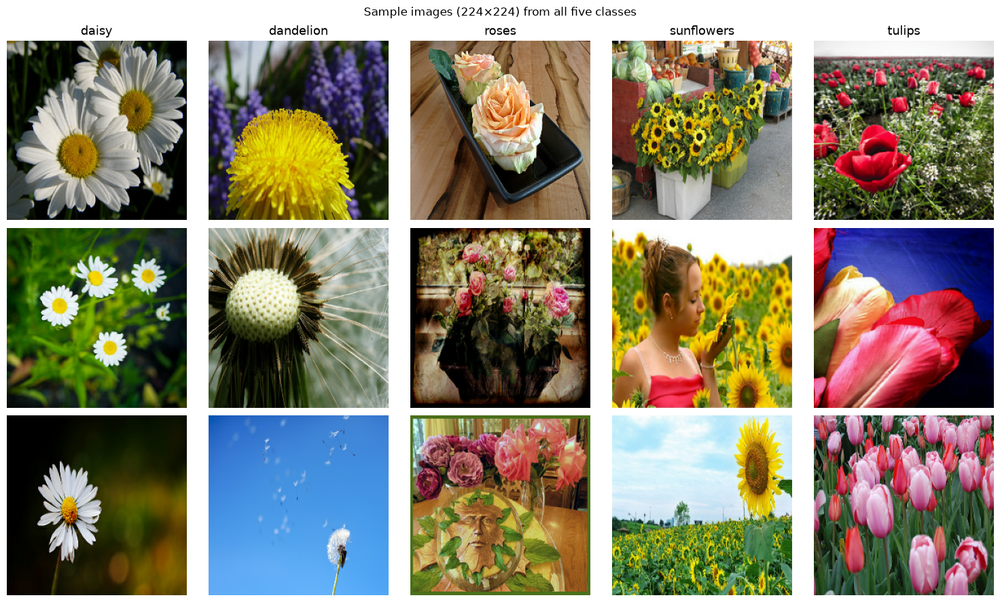

In [10]:
rng = np.random.RandomState(0)
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for c in range(NUM_CLASSES):
    ids = rng.choice(np.where(y_all == c)[0], 3, replace=False)
    for r, i in enumerate(ids):
        axes[r, c].imshow(X_all[i]); axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(CLASS_NAMES[c], fontsize=13)
plt.suptitle("Sample images (224×224) from all five classes"); plt.tight_layout()
save_fig("sample_images"); plt.show()

### The fixed 70 : 15 : 15 split

In [11]:
SPLIT_FILE = os.path.join(BASE_DIR, "split_indices.npz")     # shared by quick/full runs
if os.path.exists(SPLIT_FILE):
    s = np.load(SPLIT_FILE); idx_train, idx_val, idx_test = s["train"], s["val"], s["test"]
    print("Loaded the existing split from disk (guarantees identical samples in every run).")
else:
    idx = np.arange(len(y_all))
    idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=SEED)
    idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=y_all[idx_tmp], random_state=SEED)
    atomic_savez(SPLIT_FILE, train=idx_train, val=idx_val, test=idx_test)

assert len(set(idx_train) & set(idx_val)) == 0 and len(set(idx_train) & set(idx_test)) == 0 \
       and len(set(idx_val) & set(idx_test)) == 0, "splits overlap!"
X_tr, y_tr = X_all[idx_train], y_all[idx_train]
X_va, y_va = X_all[idx_val],   y_all[idx_val]
X_te, y_te = X_all[idx_test],  y_all[idx_test]
dist = pd.DataFrame({n: [(y == c).sum() for y in (y_tr, y_va, y_te)] for c, n in enumerate(CLASS_NAMES)},
                    index=["train", "val", "test"])
dist["total"] = dist.sum(axis=1)
print(f"train={len(y_tr)}  val={len(y_va)}  test={len(y_te)}  ({len(y_tr)/len(y_all):.0%}/{len(y_va)/len(y_all):.0%}/{len(y_te)/len(y_all):.0%})")
display(dist)

train=2569  val=550  test=551  (70%/15%/15%)


,daisy,dandelion,roses,sunflowers,tulips,total
train,443,629,449,489,559,2569
val,95,134,96,105,120,550
test,95,135,96,105,120,551


### Preprocessing + augmentation pipeline

A fresh augmenter is built **per experiment with the same seed**, so every model sees the same augmentation recipe. Validation and test data are **never augmented**.

On the Mac the whole input pipeline (shuffling, augmentation, ResNet preprocessing) is pinned to the **CPU** and prefetched, so the GPU only runs the network and never waits for the augmentation ops (some of which have no Metal kernel).

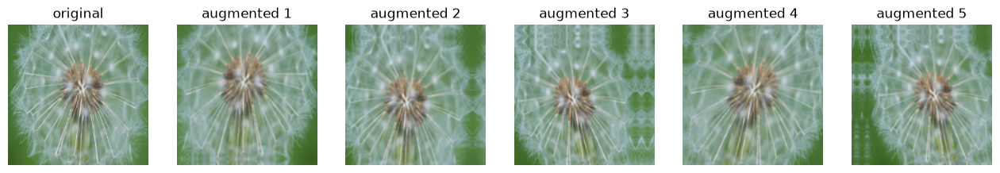

preprocessed batch: (32, 224, 224, 3) | value range after ResNet preprocessing: [-123.7, 151.1]


In [12]:
def build_augmenter(seed):
    return keras.Sequential([
        layers.RandomFlip("horizontal", seed=seed),
        layers.RandomRotation(0.05, seed=seed),          # about ±18 degrees
        layers.RandomZoom(0.1, seed=seed),
        layers.RandomTranslation(0.1, 0.1, seed=seed),
        layers.RandomContrast(0.1, seed=seed),
    ], name="augment")

def make_ds(X, y, train=False, seed=SEED):
    with tf.device("/CPU:0"):                       # data + augmentation on the CPU, the model on the GPU
        ds = tf.data.Dataset.from_tensor_slices((X, y))
        if train:
            ds = ds.shuffle(len(X), seed=seed, reshuffle_each_iteration=True)
        ds = ds.batch(BATCH_SIZE)
        if train:
            aug = build_augmenter(seed)
            ds = ds.map(lambda a, b: (tf.clip_by_value(aug(tf.cast(a, tf.float32), training=True), 0., 255.), b),
                        num_parallel_calls=1)
        ds = ds.map(lambda a, b: (preprocess_input(tf.cast(a, tf.float32)), tf.one_hot(b, NUM_CLASSES)),
                    num_parallel_calls=tf.data.AUTOTUNE)
        return ds.prefetch(tf.data.AUTOTUNE)

VAL_DS  = make_ds(X_va, y_va)
TEST_DS = make_ds(X_te, y_te)          # order preserved -> predictions align with y_te

# visual check of the augmentation recipe
with tf.device("/CPU:0"):
    aug_demo = build_augmenter(SEED)
    img0 = X_tr[0].astype("float32")[None]
    demo = [np.clip(keras.ops.convert_to_numpy(aug_demo(img0, training=True))[0], 0, 255).astype("uint8") for _ in range(5)]
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(X_tr[0]); axes[0].set_title("original"); axes[0].axis("off")
for k in range(1, 6):
    axes[k].imshow(demo[k - 1]); axes[k].set_title(f"augmented {k}"); axes[k].axis("off")
plt.show()
xb, yb = next(iter(TEST_DS))
print("preprocessed batch:", xb.shape, "| value range after ResNet preprocessing: [%.1f, %.1f]" % (xb.numpy().min(), xb.numpy().max()))

---
# Part 4 · ResNet50 and its Feature Hierarchy (§4, §5)

ResNet50 = a **stem** (7×7 conv + max-pool) followed by four stages of **bottleneck residual blocks** (3, 4, 6, 3 blocks). A bottleneck block is `1×1 conv (reduce) → 3×3 conv → 1×1 conv (expand)` plus a **skip connection** `y = F(x) + x`.

Going deeper, the first block of each new stage uses stride 2, so **resolution halves while channels double**:

| Stage | Resolution | Channels | Typical content |
|---|---|---|---|
| Stem + MaxPool | 56×56 | 64 | edges, colours, orientations |
| conv2_x | 56×56 | 256 | simple textures, boundaries |
| conv3_x | 28×28 | 512 | local patterns, petal parts, repeated structures |
| conv4_x | 14×14 | 1024 | flower parts, shape arrangements |
| conv5_x | 7×7 | 2048 | high-level, class-discriminative semantics |

Let us **verify this on the real network** instead of just trusting the table.

In [13]:
tmp = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
STAGES = [("Stem + MaxPool", "pool1_pool", ("conv1", "pool1")),
          ("conv2_x", "conv2_block3_out", ("conv2_",)),
          ("conv3_x", "conv3_block4_out", ("conv3_",)),
          ("conv4_x", "conv4_block6_out", ("conv4_",)),
          ("conv5_x", "conv5_block3_out", ("conv5_",))]
rows = []
for stage, lname, prefixes in STAGES:
    shp = tmp.get_layer(lname).output.shape[1:]
    n_par = sum(l.count_params() for l in tmp.layers if l.name.startswith(prefixes))
    rows.append({"Stage": stage, "Output layer": lname, "H×W": f"{shp[0]}×{shp[1]}", "C": shp[2],
                 "Parameters": n_par})
display(pd.DataFrame(rows))
print("Total backbone parameters:", f"{tmp.count_params():,}")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step


,Stage,Output layer,H×W,C,Parameters
0,Stem + MaxPool,pool1_pool,56×56,64,9728
1,conv2_x,conv2_block3_out,56×56,256,220032
2,conv3_x,conv3_block4_out,28×28,512,1230336
3,conv4_x,conv4_block6_out,14×14,1024,7129088
4,conv5_x,conv5_block3_out,7×7,2048,14998528


Total backbone parameters: 23,587,712


### Seeing early → late features
For one test image we take the output of each stage and show (i) the **mean activation over channels** and (ii) the **single most active channel**. Expect low-level, high-resolution detail early and coarse, blob-like semantic responses late.

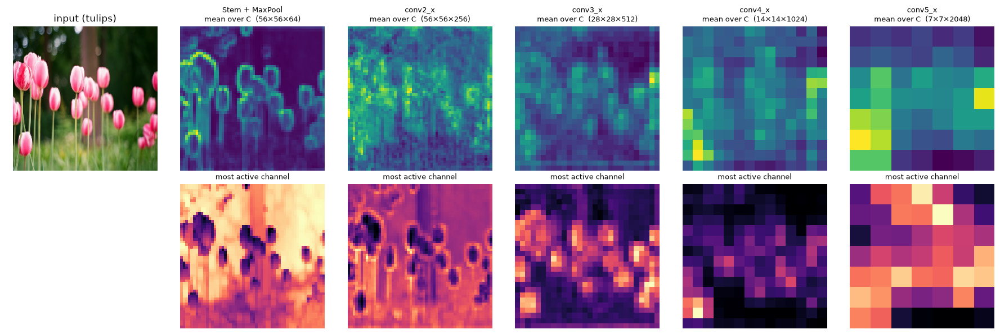

11540

In [14]:
demo_i = 3
demo_img = X_te[demo_i]
ext = keras.Model(tmp.input, [tmp.get_layer(l).output for _, l, _ in STAGES])
fmaps = ext(preprocess_input(demo_img.astype("float32")[None]), training=False)
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
axes[0, 0].imshow(demo_img); axes[0, 0].set_title(f"input ({CLASS_NAMES[y_te[demo_i]]})"); axes[1, 0].axis("off")
for k, ((stage, _, _), fm) in enumerate(zip(STAGES, fmaps), start=1):
    fm = fm.numpy()[0]
    axes[0, k].imshow(fm.mean(-1), cmap="viridis"); axes[0, k].set_title(f"{stage}\nmean over C  ({fm.shape[0]}×{fm.shape[1]}×{fm.shape[2]})", fontsize=9)
    axes[1, k].imshow(fm[..., fm.mean((0, 1)).argmax()], cmap="magma"); axes[1, k].set_title("most active channel", fontsize=9)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); save_fig("resnet_feature_hierarchy"); plt.show()
del ext, fmaps; gc.collect()          # (tmp is kept: it is small and not used for training)

**Reading the figure:** early maps still resemble the image (edges, colour blobs); late maps are tiny and no longer look like the picture – they encode *“where the flower-ness is”*. That is why one attention module can behave very differently depending on where it is inserted.

---
# Part 5 · Why Attention Position Matters (§6, §7)

An attention module receives `F ∈ ℝ^{H×W×C}`. The *values* of `H, W, C` and the *meaning* of the tensor change with depth:

* **Early (P1)** – high resolution, low-level information. Spatial attention has many positions to choose from, but each carries little semantics. Self-attention would be very expensive.
* **Middle (P2, P3)** – both spatial structure and semantics. A natural place for combined *what + where* attention.
* **Late (P4)** – 7×7, very semantic. Few positions to weight spatially, but channel attention can re-weight highly semantic channels.

Candidate positions: **P1** after conv2_x, **P2** after conv3_x, **P3** after conv4_x, **P4** after conv5_x. The sheet says to concentrate on **P2, P3, P4** (P1 is costly), but Experiment B1 includes P1 so the position ablation is complete.

Two questions the lab asks you to answer *experimentally*: **Which** attention mechanism? **Where** to insert it?

---
# Part 6 · Attention Modules (§9 – §12, §19)

All modules below are **shape-preserving** (`H×W×C` in → `H×W×C` out) so they can be dropped between two ResNet stages without touching the pretrained weights. Each module implements:
* `call(x)` – normal forward pass, returns the refined features;
* `get_maps(x)` – returns the **internal attention weights** (channel weights, spatial map, self-attention matrix) so we can visualise them later (§28).

### 6.1 Channel attention (§9) – “what is important?”
$$z_c=\frac1{HW}\sum_{i,j}F(i,j,c),\qquad M_c(F)=\sigma\big(W_2\,\delta(W_1 z)\big),\qquad F_c=F\odot M_c(F)$$
`W₁` squeezes `C → C/r`, `W₂` restores `C/r → C`, δ = ReLU, σ = sigmoid, `r = 16`. (This is mathematically the **Squeeze-and-Excitation block**, so “Channel / SE” is one row in the sheet's comparison table.)

### 6.2 Spatial attention (§10) – “where is it important?”
$$F_{avg}=\text{Mean}_c(F),\quad F_{max}=\text{Max}_c(F),\quad M_s(F)=\sigma\big(\text{Conv}_{k\times k}([F_{avg}\Vert F_{max}])\big),\quad F'_s=F\odot M_s(F)$$

### 6.3 Sequential channel→spatial (§11)
`F_c = M_c(F) ⊙ F`, then `F_cs = M_s(F_c) ⊙ F_c` – first *what*, then *where*. The reverse order (spatial→channel) is Experiment 4.

### 6.4 Self-attention (§12) – “which positions relate to which?”
Flatten `F → X ∈ ℝ^{N×C}` with `N = HW`; `Q = XW_Q, K = XW_K, V = XW_V`;
$$A=\text{softmax}\!\left(\frac{QK^\top}{\sqrt d}\right)\in\mathbb R^{N\times N},\quad Y=AV,\quad F_{SA}=F+\gamma\,\text{reshape}(Y)$$
`γ` is a learnable scalar initialised at 0 (so training starts from the unmodified pretrained features and *learns* how much attention to mix in). `Q,K` use `d = C/8` (lightweight); `V` keeps `C` so the residual can be added. **Cost grows with N²** → use at P3/P4.

### 6.5 Additional established mechanisms (§19)
* **ECA** – no dimensionality reduction; a *1-D convolution* of adaptive kernel size over the channel descriptor (cheap, local cross-channel interaction).
* **CBAM** – channel attention using *both* avg- and max-pooled descriptors through a shared MLP, followed by spatial attention (7×7).
* **Coordinate Attention** – pools along H and W *separately* to keep positional information, then produces one attention vector per axis.
* **SE** – identical to the channel attention above.

In [15]:
class BaseAttention(layers.Layer):
    """forward(x) -> (refined_features, dict_of_internal_maps).  call() returns only the features."""
    def forward(self, x):
        raise NotImplementedError
    def call(self, x):
        return self.forward(x)[0]
    def get_maps(self, x):
        return self.forward(x)[1]
    def compute_output_shape(self, input_shape):
        return input_shape


class ChannelAttention(BaseAttention):
    def __init__(self, ratio=16, **kw):
        super().__init__(**kw); self.ratio = ratio
    def build(self, input_shape):
        C = int(input_shape[-1]); h = max(C // self.ratio, 1)
        self.fc1 = layers.Dense(h, activation="relu", name="fc_reduce")      # W1
        self.fc2 = layers.Dense(C, activation="sigmoid", name="fc_restore")  # W2
        self.fc1.build((None, C)); self.fc2.build((None, h))
    def forward(self, x):
        z = tf.reduce_mean(x, axis=[1, 2])                  # (B, C) channel descriptor
        m = self.fc2(self.fc1(z))                           # (B, C) weights in (0,1)
        return x * m[:, None, None, :], {"channel_weights": m}
    def get_config(self):
        return {**super().get_config(), "ratio": self.ratio}


class SEAttention(ChannelAttention):
    """Squeeze-and-Excitation: identical computation to ChannelAttention (kept as a named alias)."""


class SpatialAttention(BaseAttention):
    def __init__(self, kernel_size=7, **kw):
        super().__init__(**kw); self.kernel_size = kernel_size
    def build(self, input_shape):
        self.conv = layers.Conv2D(1, self.kernel_size, padding="same", activation="sigmoid", name="spatial_conv")
        self.conv.build((None, input_shape[1], input_shape[2], 2))
    def forward(self, x):
        avg = tf.reduce_mean(x, axis=-1, keepdims=True)
        mx = tf.reduce_max(x, axis=-1, keepdims=True)
        m = self.conv(tf.concat([avg, mx], axis=-1))        # (B, H, W, 1)
        return x * m, {"spatial_map": m[..., 0]}
    def get_config(self):
        return {**super().get_config(), "kernel_size": self.kernel_size}


class SelfAttention(BaseAttention):
    def __init__(self, qk_ratio=8, **kw):
        super().__init__(**kw); self.qk_ratio = qk_ratio
    def build(self, input_shape):
        C = int(input_shape[-1]); self.d = max(C // self.qk_ratio, 1)
        self.wq = layers.Dense(self.d, use_bias=False, name="W_Q")
        self.wk = layers.Dense(self.d, use_bias=False, name="W_K")
        self.wv = layers.Dense(C, use_bias=False, name="W_V")
        for l, out in ((self.wq, self.d), (self.wk, self.d), (self.wv, C)):
            l.build((None, C))
        self.gamma = self.add_weight(name="gamma", shape=(), initializer="zeros", trainable=True)
    def forward(self, x):
        H, W, C = x.shape[1], x.shape[2], x.shape[3]
        B = tf.shape(x)[0]
        X = tf.reshape(x, (B, H * W, C))                    # (B, N, C)
        Q, K, V = self.wq(X), self.wk(X), self.wv(X)
        A = tf.nn.softmax(tf.matmul(Q, K, transpose_b=True) / math.sqrt(self.d), axis=-1)  # (B, N, N)
        Y = tf.reshape(tf.matmul(A, V), (B, H, W, C))
        return x + self.gamma * Y, {"attention_matrix": A, "self_attention_response": tf.reduce_mean(tf.abs(Y), axis=-1)}
    def get_config(self):
        return {**super().get_config(), "qk_ratio": self.qk_ratio}


class ECAAttention(BaseAttention):
    def build(self, input_shape):
        C = int(input_shape[-1]); t = int(abs((math.log2(C) + 1) / 2))
        self.k = t if t % 2 else t + 1                      # adaptive odd kernel size
        self.conv = layers.Conv1D(1, self.k, padding="same", use_bias=False, name="eca_conv")
        self.conv.build((None, C, 1))
    def forward(self, x):
        z = tf.reduce_mean(x, axis=[1, 2])[..., None]       # (B, C, 1)
        m = tf.sigmoid(self.conv(z))[..., 0]                # (B, C)
        return x * m[:, None, None, :], {"channel_weights": m}


class CBAMAttention(BaseAttention):
    def __init__(self, ratio=16, kernel_size=7, **kw):
        super().__init__(**kw); self.ratio, self.kernel_size = ratio, kernel_size
    def build(self, input_shape):
        C = int(input_shape[-1]); h = max(C // self.ratio, 1)
        self.fc1 = layers.Dense(h, activation="relu", name="mlp_reduce")
        self.fc2 = layers.Dense(C, name="mlp_restore")
        self.fc1.build((None, C)); self.fc2.build((None, h))
        self.conv = layers.Conv2D(1, self.kernel_size, padding="same", activation="sigmoid", name="spatial_conv")
        self.conv.build((None, input_shape[1], input_shape[2], 2))
    def forward(self, x):
        avg, mx = tf.reduce_mean(x, axis=[1, 2]), tf.reduce_max(x, axis=[1, 2])
        mc = tf.sigmoid(self.fc2(self.fc1(avg)) + self.fc2(self.fc1(mx)))      # shared MLP
        xc = x * mc[:, None, None, :]
        s = tf.concat([tf.reduce_mean(xc, -1, keepdims=True), tf.reduce_max(xc, -1, keepdims=True)], -1)
        ms = self.conv(s)
        return xc * ms, {"channel_weights": mc, "spatial_map": ms[..., 0]}
    def get_config(self):
        return {**super().get_config(), "ratio": self.ratio, "kernel_size": self.kernel_size}


class CoordAttention(BaseAttention):
    def __init__(self, reduction=32, **kw):
        super().__init__(**kw); self.reduction = reduction
    def build(self, input_shape):
        H, W, C = int(input_shape[1]), int(input_shape[2]), int(input_shape[3])
        mip = max(8, C // self.reduction)
        self.conv1 = layers.Conv2D(mip, 1, name="coord_reduce"); self.bn = layers.BatchNormalization(name="coord_bn")
        self.conv_h = layers.Conv2D(C, 1, name="coord_h"); self.conv_w = layers.Conv2D(C, 1, name="coord_w")
        self.conv1.build((None, H + W, 1, C)); self.bn.build((None, H + W, 1, mip))
        self.conv_h.build((None, H, 1, mip)); self.conv_w.build((None, W, 1, mip))
    def forward(self, x):
        H, W = x.shape[1], x.shape[2]
        xh = tf.reduce_mean(x, axis=2, keepdims=True)                              # (B,H,1,C)
        xw = tf.transpose(tf.reduce_mean(x, axis=1, keepdims=True), [0, 2, 1, 3])  # (B,W,1,C)
        y = self.conv1(tf.concat([xh, xw], axis=1)); y = self.bn(y)
        y = y * tf.nn.relu6(y + 3.0) / 6.0                                         # h-swish
        yh, yw = tf.split(y, [H, W], axis=1)
        ah = tf.sigmoid(self.conv_h(yh))                                           # (B,H,1,C)
        aw = tf.transpose(tf.sigmoid(self.conv_w(yw)), [0, 2, 1, 3])               # (B,1,W,C)
        return x * ah * aw, {"spatial_map": tf.reduce_mean(ah * aw, axis=-1)}
    def get_config(self):
        return {**super().get_config(), "reduction": self.reduction}


_ATOMS = {"channel": lambda r, k: ChannelAttention(r), "spatial": lambda r, k: SpatialAttention(k),
          "self": lambda r, k: SelfAttention()}

class SequentialAttention(BaseAttention):
    """Applies atoms one after another in the given order, e.g. ('channel','spatial') or ('spatial','channel')."""
    def __init__(self, order=("channel", "spatial"), ratio=16, kernel_size=7, **kw):
        super().__init__(**kw)
        self.order, self.ratio, self.kernel_size = tuple(order), ratio, kernel_size
        self.blocks = [_ATOMS[o](ratio, kernel_size) for o in self.order]
    def build(self, input_shape):
        for b in self.blocks:
            b.build(input_shape)
    def forward(self, x):
        maps = {}
        for b in self.blocks:
            x, m = b.forward(x); maps.update(m)
        return x, maps
    def get_config(self):
        return {**super().get_config(), "order": list(self.order), "ratio": self.ratio, "kernel_size": self.kernel_size}


def make_attention(kind, name=None, ratio=REDUCTION, kernel_size=7):
    kind = kind.lower()
    if kind == "channel":  return ChannelAttention(ratio, name=name)
    if kind == "spatial":  return SpatialAttention(kernel_size, name=name)
    if kind == "cs":       return SequentialAttention(("channel", "spatial"), ratio, kernel_size, name=name)
    if kind == "sc":       return SequentialAttention(("spatial", "channel"), ratio, kernel_size, name=name)
    if kind == "self":     return SelfAttention(name=name)
    if kind == "combined": return SequentialAttention(("channel", "spatial", "self"), ratio, kernel_size, name=name)
    if kind == "se":       return SEAttention(ratio, name=name)
    if kind == "eca":      return ECAAttention(name=name)
    if kind == "cbam":     return CBAMAttention(ratio, kernel_size, name=name)
    if kind == "coord":    return CoordAttention(name=name)
    raise ValueError(f"unknown attention kind: {kind}")

### Unit test: shape preservation + module complexity at each position

The sheet requires that *attention must not modify spatial/channel dimensions*. We verify it for every module at every position, and count the parameters each module adds (this is the **pre-training complexity analysis**, before we spend GPU time).

In [16]:
POS_SHAPES = {"P1": (56, 56, 256), "P2": (28, 28, 512), "P3": (14, 14, 1024), "P4": (7, 7, 2048)}
KINDS = ["channel", "spatial", "cs", "sc", "self", "combined", "eca", "cbam", "coord"]
rows = []
for kind in KINDS:
    row = {"module": kind}
    for pos, (H, W, C) in POS_SHAPES.items():
        layer = make_attention(kind)
        x = tf.random.normal((2, H, W, C))
        y = layer(x)
        assert y.shape == x.shape, f"{kind}@{pos} changed shape {x.shape}->{y.shape}"
        maps = layer.get_maps(x)
        row[pos] = sum(int(np.prod(w.shape)) for w in layer.weights)
    rows.append(row)
mod_params = pd.DataFrame(rows).set_index("module")
print("✅ every module preserves (H, W, C) at every position\n\nParameters added by each attention module:")
display(mod_params)

✅ every module preserves (H, W, C) at every position

Parameters added by each attention module:


,P1,P2,P3,P4
module,,,,
channel,8464,33312,132160,526464
spatial,99,99,99,99
cs,8563,33411,132259,526563
sc,8563,33411,132259,526563
self,81921,327681,1310721,5242881
combined,90484,361092,1442980,5769444
eca,5,5,5,7
cbam,8563,33411,132259,526563
coord,6696,25680,100512,397632


### Self-attention cost: why N² matters (Questions 13, 14)
The attention matrix `A` has `N × N` entries per image, `N = H·W`. Halving the resolution divides `N` by 4 and the matrix by **16**.

,Position,H×W,N=H·W,A entries (N²),"A size / image (MB, fp32)"
0,P1,56×56,3136,9834496,39.337984
1,P2,28×28,784,614656,2.458624
2,P3,14×14,196,38416,0.153664
3,P4,7×7,49,2401,0.009604


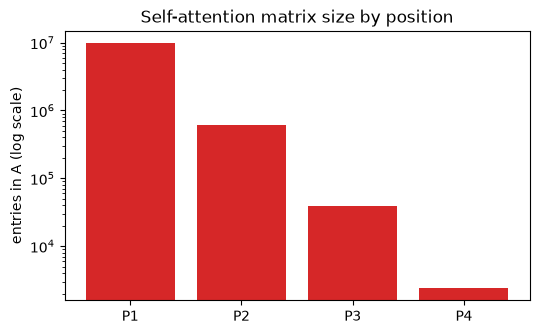

In [17]:
cost = pd.DataFrame([{"Position": p, "H×W": f"{H}×{W}", "N=H·W": H * W, "A entries (N²)": (H * W) ** 2,
                      "A size / image (MB, fp32)": (H * W) ** 2 * 4 / 1e6} for p, (H, W, C) in POS_SHAPES.items()])
display(cost)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(cost["Position"], cost["A entries (N²)"], color="tab:red"); ax.set_yscale("log")
ax.set_ylabel("entries in A (log scale)"); ax.set_title("Self-attention matrix size by position")
save_fig("self_attention_cost"); plt.show()

---
# Part 7 · Inserting Attention, Transfer Learning, Loss, Metrics, Protocol (§8, §13, §20 – §22, §34)

## 7.1 How attention is inserted (§13)
We cut the pretrained ResNet50 into four segments that **share the original pretrained layers** (no weights are copied or lost):

```
image → [stem + conv2_x] → P1 → [conv3_x] → P2 → [conv4_x] → P3 → [conv5_x] → P4 → GAP → Dropout → Dense(5) → softmax
```
An attention module may be placed at any `Pk`. The builder **records the tensor shape immediately before and after each attention block** (observation #1 of §38) and asserts they are identical.

**Baseline (§8)** = the same network with *no* attention: `ResNet50 → GAP → Dropout → Dense(5)`.

## 7.2 Transfer-learning recipe (§20)
1. Load ResNet50 (ImageNet weights, `include_top=False`). 2. Insert attention. 3. GAP → Dropout → Dense(5).
4. **Phase 1:** freeze all backbone layers, train attention + head (`lr = 1e-3`).
5. **Phase 2:** unfreeze the final stage `conv5_x` (BatchNorm layers stay frozen, which is standard good practice for small datasets) and fine-tune everything trainable at `lr = 1e-4`.

## 7.3 Loss (§21)
Categorical cross-entropy: $\;L_{CE}=-\frac1N\sum_{i}\sum_{c=1}^{5}y_{i,c}\log\hat y_{i,c}$.

## 7.4 Metrics (§22)
Accuracy; macro precision/recall/F1 (`F1_c = 2PR/(P+R)`, macro = mean over the 5 classes); trainable and total parameters; mean inference time per image.

In [18]:
POSITIONS = ["P1", "P2", "P3", "P4"]
STAGE_OUT = {"P1": "conv2_block3_out", "P2": "conv3_block4_out", "P3": "conv4_block6_out", "P4": "conv5_block3_out"}
SEG_NAMES = ["stem_conv2x", "conv3x", "conv4x", "conv5x"]
SHAPE_LOG = []     # observation #1: tensor shape before / after every attention module


def build_model(attn_spec=None, name="model", verbose=True):
    """attn_spec: {'P3': ('cs', {'kernel_size': 7}), 'P4': (...)}.  Returns (model, backbone_layers)."""
    attn_spec = attn_spec or {}
    base = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    outs = [base.get_layer(STAGE_OUT[p]).output for p in POSITIONS]
    segs = [keras.Model(base.input, outs[0], name=SEG_NAMES[0])]
    for i in range(1, 4):                                   # sub-models re-use the pretrained layers
        segs.append(keras.Model(outs[i - 1], outs[i], name=SEG_NAMES[i]))
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    x = inp
    for pos, seg in zip(POSITIONS, segs):
        x = seg(x)
        if pos in attn_spec:
            kind, kw = attn_spec[pos]
            att = make_attention(kind, name=f"att_{kind}_{pos}", **kw)
            before = tuple(x.shape[1:]); x = att(x); after = tuple(x.shape[1:])
            assert before == after, f"attention changed the shape at {pos}: {before} -> {after}"
            if verbose:
                SHAPE_LOG.append({"model": name, "position": pos, "attention": kind, "before": before, "after": after})
                print(f"  [{name}] {pos}: {kind:9s} input {before} -> output {after}")
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(DROPOUT, name="dropout")(x)
    logits = layers.Dense(NUM_CLASSES, name="logits")(x)
    probs = layers.Activation("softmax", dtype="float32", name="probs")(logits)
    return keras.Model(inp, probs, name=name), base.layers


def set_backbone_trainable(backbone_layers, unfreeze_prefix=None):
    for l in backbone_layers:
        l.trainable = False
    if unfreeze_prefix:
        for l in backbone_layers:
            if l.name.startswith(unfreeze_prefix) and not isinstance(l, layers.BatchNormalization):
                l.trainable = True

n_params   = lambda ws: int(sum(np.prod(w.shape) for w in ws))
attn_params = lambda m: int(sum(n_params(l.weights) for l in m.layers if l.name.startswith("att_")))

### Experiment registry
Every experiment is just a dictionary `{position: (attention_kind, options)}`. **Only the factor under study differs between rows**, which is the whole point of an ablation.

| ID | Study | Configuration |
|---|---|---|
| A0 | Exp 1 | baseline (no attention) |
| A1 / A2 / A3 / A4 / A5 | Exp 1 | channel / spatial / channel→spatial / self / combined (ch→sp→self), all at **P3** |
| B1 / B2 / B3 / B4 | Exp 2 | channel→spatial at P1 / P2 / P3 / P4 (**B3 = A3**) |
| C (P3, P4) | Exp 3 | P3 only (=A3), P4 only (=B4), **P3+P4**, **P2+P3+P4** |
| D1 | Exp 4 | spatial→channel at P3 (compare with A3) |
| E1 / E2 / E3 | Exp 5 | spatial kernel 3 / 5 / 7 (**E3 = A3**), channel→spatial at P3 |
| F1 / F2 / F3 | Additional | ECA / CBAM / Coordinate at P3 (SE ≡ A1) |

Aliases (e.g. B3 = A3) mean the identical configuration is trained **once** and reused, which is both cheaper and perfectly consistent.

In [19]:
EXPERIMENTS = {
    "A0_Baseline":       {},
    "A1_Channel_P3":     {"P3": ("channel", {})},
    "A2_Spatial_P3":     {"P3": ("spatial", {})},
    "A3_ChSp_P3":        {"P3": ("cs", {})},
    "A4_Self_P3":        {"P3": ("self", {})},
    "A5_Combined_P3":    {"P3": ("combined", {})},
    "B1_ChSp_P1":        {"P1": ("cs", {})},
    "B2_ChSp_P2":        {"P2": ("cs", {})},
    "B4_ChSp_P4":        {"P4": ("cs", {})},
    "C3_ChSp_P3P4":      {"P3": ("cs", {}), "P4": ("cs", {})},
    "C4_ChSp_P2P3P4":    {"P2": ("cs", {}), "P3": ("cs", {}), "P4": ("cs", {})},
    "D1_SpCh_P3":        {"P3": ("sc", {})},
    "E1_ChSp_k3_P3":     {"P3": ("cs", {"kernel_size": 3})},
    "E2_ChSp_k5_P3":     {"P3": ("cs", {"kernel_size": 5})},
    "F1_ECA_P3":         {"P3": ("eca", {})},
    "F2_CBAM_P3":        {"P3": ("cbam", {})},
    "F3_Coord_P3":       {"P3": ("coord", {})},
    "G1_Self_P4":        {"P4": ("self", {})},        # optional: self-attention at the other recommended position
}
ALIAS = {"B3_ChSp_P3": "A3_ChSp_P3", "E3_ChSp_k7_P3": "A3_ChSp_P3", "C1_ChSp_P3": "A3_ChSp_P3",
         "C2_ChSp_P4": "B4_ChSp_P4", "F0_SE_P3": "A1_Channel_P3"}
MANDATORY = ["A0_Baseline", "A1_Channel_P3", "A2_Spatial_P3", "A3_ChSp_P3", "B2_ChSp_P2", "B4_ChSp_P4", "A4_Self_P3"]  # §35
print(len(EXPERIMENTS), "trainable configurations;", len(MANDATORY), "are in the minimum mandatory set (§35).")

18 trainable configurations; 7 are in the minimum mandatory set (§35).


### Training, evaluation and bookkeeping

`run_experiment(name)` does everything for one model: build → Phase 1 → Phase 2 → restore best-validation weights → evaluate on the untouched test set → save weights, curves and metrics to disk. It **skips experiments that already finished**, so you can stop and continue at any time (an experiment that was interrupted starts again from epoch 1). Between experiments the Keras session is cleared so GPU memory does not pile up on the Mac.

Recorded (§38): training/validation/test accuracy & loss, macro P/R/F1, trainable and total parameters, attention-module parameters, inference time per image, confusion matrix, predictions.

In [20]:
class KeepBest(keras.callbacks.Callback):
    """Remember the weights of the epoch with the lowest validation loss (across both phases)."""
    def __init__(self):
        super().__init__(); self.best, self.w, self.best_epoch, self.n = np.inf, None, 0, 0
    def on_epoch_end(self, epoch, logs=None):
        self.n += 1
        if logs["val_loss"] < self.best:
            self.best, self.w, self.best_epoch = logs["val_loss"], self.model.get_weights(), self.n
    def restore(self):
        self.model.set_weights(self.w)


def time_inference(model, ds, repeats=3):
    batches = [xb for xb, _ in ds]                       # pre-load: time the model, not the input pipeline
    for xb in batches[:2]:
        model(xb, training=False).numpy()                # warm-up
    per_img = []
    for _ in range(repeats):
        n, t0 = 0, time.perf_counter()
        for xb in batches:
            model(xb, training=False).numpy(); n += int(xb.shape[0])
        per_img.append((time.perf_counter() - t0) / n)
    return 1000.0 * float(np.median(per_img))            # milliseconds per image


def evaluate_model(model, test_ds, y_true):
    probs = model.predict(test_ds, verbose=0); y_pred = probs.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    f_c = precision_recall_fscore_support(y_true, y_pred, average=None, zero_division=0)[2]
    return dict(accuracy=float(accuracy_score(y_true, y_pred)), precision=float(p), recall=float(r), f1=float(f),
                f1_per_class=[float(v) for v in f_c],
                test_loss=float(-np.mean(np.log(probs[np.arange(len(y_true)), y_true] + 1e-12))),
                confusion=confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES)).tolist(),
                y_pred=[int(v) for v in y_pred])


RESULTS_PATH = os.path.join(OUT_DIR, "results.json")
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
resolve = lambda n: ALIAS.get(n, n)
TOTAL_EPOCHS = EPOCHS_FROZEN + EPOCHS_FT
HIST_KEYS = ["accuracy", "val_accuracy", "loss", "val_loss"]


def compile_model(model, lr):
    # jit_compile=False: XLA is not supported by the Metal plugin, so it must stay off on the Mac
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="categorical_crossentropy",
                  metrics=["accuracy"], jit_compile=False)


def run_experiment(name, seed=SEED, force=False):
    key = name if seed == SEED else f"{name}__seed{seed}"
    if key in RESULTS and not force:
        print(f"⏭  {key}: already done (acc={RESULTS[key]['accuracy']:.4f}) – skipping"); return RESULTS[key]
    print(f"\n{'='*78}\n▶ {key}   spec={EXPERIMENTS[name]}\n{'='*78}")
    keras.backend.clear_session()                        # release the previous model's GPU memory
    keras.utils.set_random_seed(seed)
    model, backbone = build_model(EXPERIMENTS[name], name=key.replace("__", "_"))
    set_backbone_trainable(backbone, None);    trainable_stage1 = n_params(model.trainable_weights)
    set_backbone_trainable(backbone, "conv5"); trainable_ft = n_params(model.trainable_weights)

    keep, hist = KeepBest(), {k: [] for k in HIST_KEYS}
    train_ds = make_ds(X_tr, y_tr, train=True, seed=seed)
    t0 = time.time()
    # Phase 1: backbone frozen, train attention + head.  Phase 2: unfreeze conv5_x (BatchNorm stays frozen) and fine-tune.
    for phase, lr, first, last in ((1, LR_HEAD, 0, EPOCHS_FROZEN), (2, LR_FT, EPOCHS_FROZEN, TOTAL_EPOCHS)):
        set_backbone_trainable(backbone, None if phase == 1 else "conv5")
        compile_model(model, lr)
        plateau = keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=0)
        h = model.fit(train_ds, validation_data=VAL_DS, initial_epoch=first, epochs=last, verbose=VERBOSE,
                      callbacks=[keep, plateau])
        for k in HIST_KEYS: hist[k] += [float(v) for v in h.history[k]]
    train_time = time.time() - t0
    if keep.w is not None: keep.restore()               # weights of the best-validation epoch

    res = evaluate_model(model, TEST_DS, y_te)
    res.update(name=key, position=sorted(EXPERIMENTS[name].keys()), history=hist, phase_boundary=EPOCHS_FROZEN,
               best_epoch=keep.best_epoch, train_time_s=train_time,
               total_params=int(model.count_params()), trainable_params_ft=trainable_ft,
               trainable_params_stage1=trainable_stage1, attn_params=attn_params(model),
               inference_ms=time_inference(model, TEST_DS), seed=seed,
               train_acc_final=hist["accuracy"][-1], val_acc_best=float(max(hist["val_accuracy"])))
    atomic_save_weights(model, os.path.join(OUT_DIR, f"{key}.weights.h5"))
    RESULTS[key] = res; atomic_json(RESULTS, RESULTS_PATH)
    print(f"✔ {key}: test acc={res['accuracy']:.4f}  macroF1={res['f1']:.4f}  params={res['total_params']:,}  "
          f"{res['inference_ms']:.2f} ms/img  ({train_time/60:.1f} min)")
    del model, backbone, train_ds, keep; gc.collect(); keras.backend.clear_session()
    return res


def run_group(names, **kw):
    for n in names: run_experiment(n, **kw)

### Progress status
Shows which experiments are finished and which have not started yet. Run it any time.

In [21]:
def status_table():
    rows = []
    for n in EXPERIMENTS:
        r = RESULTS.get(n)
        s = f"✅ done  (test acc {r['accuracy']:.4f}, {r['train_time_s'] / 60:.0f} min)" if r else "· not started"
        rows.append({"experiment": n, "status": s, "mandatory (§35)": "yes" if n in MANDATORY else ""})
    return pd.DataFrame(rows)
display(status_table())

,experiment,status,mandatory (§35)
0,A0_Baseline,· not started,yes
1,A1_Channel_P3,· not started,yes
2,A2_Spatial_P3,· not started,yes
3,A3_ChSp_P3,· not started,yes
4,A4_Self_P3,· not started,yes
5,A5_Combined_P3,· not started,
6,B1_ChSp_P1,· not started,
7,B2_ChSp_P2,· not started,yes
8,B4_ChSp_P4,· not started,yes
9,C3_ChSp_P3P4,· not started,


### Result-table helpers

* `results_table(rows)` builds the exact tables requested by the sheet. Missing experiments show `NaN` (not run yet).
* `noise_note()` prints the **sampling uncertainty** of test accuracy: with n ≈ 551 test images, the standard error is about ±1.2 %, so two models differing by <1.5 % are statistically indistinguishable. Use this when writing “better/worse” statements.

In [22]:
def results_table(rows, baseline="A0_Baseline"):
    COLS = ["Model", "Position", "Accuracy", "Precision", "Recall", "F1", "ΔAcc vs base", "Params (total)",
            "Params (trainable, FT)", "Attn params", "Inference (ms/img)"]
    out = []
    base_acc = RESULTS.get(baseline, {}).get("accuracy", np.nan)
    for label, pos, name in rows:
        r = RESULTS.get(resolve(name))
        if r is None:
            out.append({"Model": label, "Position": pos}); continue
        out.append({"Model": label, "Position": pos, "Accuracy": r["accuracy"], "Precision": r["precision"],
                    "Recall": r["recall"], "F1": r["f1"], "ΔAcc vs base": r["accuracy"] - base_acc,
                    "Params (total)": r["total_params"], "Params (trainable, FT)": r["trainable_params_ft"],
                    "Attn params": r["attn_params"], "Inference (ms/img)": r["inference_ms"]})
    return pd.DataFrame(out, columns=COLS)

def show_table(df):
    fmt = {c: "{:.4f}" for c in ["Accuracy", "Precision", "Recall", "F1"] if c in df}
    fmt.update({"ΔAcc vs base": "{:+.4f}", "Inference (ms/img)": "{:.2f}", "Params (total)": "{:,.0f}",
                "Params (trainable, FT)": "{:,.0f}", "Attn params": "{:,.0f}"})
    display(df.style.format({k: v for k, v in fmt.items() if k in df}, na_rep="–"))

def noise_note():
    n = len(y_te); acc = np.mean([r["accuracy"] for r in RESULTS.values()]) if RESULTS else 0.9
    se = math.sqrt(acc * (1 - acc) / n)
    print(f"Test set n={n}.  Binomial std-error of accuracy ≈ {se:.4f}  → 95% CI ≈ ±{1.96*se:.4f}.  "
          f"Gaps smaller than ~{1.96*se*math.sqrt(2):.3f} between two models are NOT statistically meaningful.")

### Smoke test (30 seconds): build the baseline and the Channel+Spatial@P3 model, check shapes and trainable parameters

In [23]:
for nm in ["A0_Baseline", "A3_ChSp_P3"]:
    m, bl = build_model(EXPERIMENTS[nm], name=f"smoke_{nm}")
    set_backbone_trainable(bl, None); t1 = n_params(m.trainable_weights)
    set_backbone_trainable(bl, "conv5"); t2 = n_params(m.trainable_weights)
    print(f"{nm}: total={m.count_params():,}  trainable phase-1={t1:,}  trainable phase-2={t2:,}  "
          f"attention params={attn_params(m):,}  output={m.output_shape}")
    del m
del bl; gc.collect(); keras.backend.clear_session()

A0_Baseline: total=23,597,957  trainable phase-1=10,245  trainable phase-2=14,963,717  attention params=0  output=(None, 5)
  [smoke_A3_ChSp_P3] P3: cs        input (14, 14, 1024) -> output (14, 14, 1024)
A3_ChSp_P3: total=23,730,216  trainable phase-1=142,504  trainable phase-2=15,095,976  attention params=132,259  output=(None, 5)


### Speed test on your Mac (≈ 1–2 min)
Trains a few real batches of the Channel+Spatial@P3 model (phase-2 setting, the slower phase) on the GPU and extrapolates the time per experiment and for the whole study. The first epoch of every real run is a bit slower (graph building), so treat the numbers as estimates.

In [24]:
def speed_test(name="A3_ChSp_P3", steps=12):
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
    m, bl = build_model(EXPERIMENTS[name], name="speedtest", verbose=False)
    set_backbone_trainable(bl, "conv5"); compile_model(m, LR_FT)
    ds = make_ds(X_tr, y_tr, train=True)
    m.fit(ds.take(3), epochs=1, verbose=0)                       # warm-up: graph tracing + Metal kernel compilation
    t0 = time.perf_counter(); m.fit(ds.take(steps), epochs=1, verbose=0); dt = (time.perf_counter() - t0) / steps
    m.evaluate(VAL_DS.take(1), verbose=0)                        # warm-up
    t0 = time.perf_counter(); m.evaluate(VAL_DS.take(4), verbose=0); dv = (time.perf_counter() - t0) / 4
    per_epoch = math.ceil(len(y_tr) / BATCH_SIZE) * dt + math.ceil(len(y_va) / BATCH_SIZE) * dv
    per_exp = per_epoch * TOTAL_EPOCHS + 60                      # + model building, evaluation and timing
    print(f"{dt * 1000:.0f} ms per training step (batch {BATCH_SIZE})  →  ≈ {per_epoch:.0f} s per epoch")
    print(f"≈ {per_exp / 60:.0f} min per experiment ({TOTAL_EPOCHS} epochs)  →  mandatory set (7): ≈ {7 * per_exp / 3600:.1f} h,"
          f"  all {len(EXPERIMENTS)} experiments: ≈ {len(EXPERIMENTS) * per_exp / 3600:.1f} h")
    del m, bl, ds; gc.collect(); keras.backend.clear_session()

speed_test()

347 ms per training step (batch 32)  →  ≈ 32 s per epoch
≈ 12 min per experiment (20 epochs)  →  mandatory set (7): ≈ 1.4 h,  all 18 experiments: ≈ 3.5 h


---
# Part 8 · The Five Main Experiments (§14 – §18, §35)

> **Protocol reminder (§34):** identical split, preprocessing, augmentation, backbone, classifier, optimizer, batch size, epochs, LR schedule, fine-tuning and metrics. *Only the factor under study changes.*

If time is short, run the **minimum mandatory set (§35)** first: A0, A1, A2, A3, B2, B4, A4 (+ Grad-CAM, position maps, comparison graph later). The cell below does exactly that. Everything else follows.

In [25]:
run_group(MANDATORY)


▶ A0_Baseline   spec={}
Epoch 1/10
81/81 - 27s - 330ms/step - accuracy: 0.6719 - loss: 0.8849 - val_accuracy: 0.8491 - val_loss: 0.4287 - learning_rate: 1.0000e-03
Epoch 2/10
81/81 - 23s - 286ms/step - accuracy: 0.8435 - loss: 0.4381 - val_accuracy: 0.8782 - val_loss: 0.3522 - learning_rate: 1.0000e-03
Epoch 3/10
81/81 - 26s - 321ms/step - accuracy: 0.8762 - loss: 0.3466 - val_accuracy: 0.8745 - val_loss: 0.3340 - learning_rate: 1.0000e-03
Epoch 4/10
81/81 - 29s - 361ms/step - accuracy: 0.8933 - loss: 0.3021 - val_accuracy: 0.8855 - val_loss: 0.3101 - learning_rate: 1.0000e-03
Epoch 5/10
81/81 - 39s - 482ms/step - accuracy: 0.8933 - loss: 0.2789 - val_accuracy: 0.8945 - val_loss: 0.2869 - learning_rate: 1.0000e-03
Epoch 6/10
81/81 - 45s - 557ms/step - accuracy: 0.9039 - loss: 0.2631 - val_accuracy: 0.8982 - val_loss: 0.2846 - learning_rate: 1.0000e-03
Epoch 7/10
81/81 - 43s - 529ms/step - accuracy: 0.9186 - loss: 0.2330 - val_accuracy: 0.8945 - val_loss: 0.2837 - learning_rate: 1.0000

## Experiment 1 – Attention-type ablation (§14)
**Question:** *How does attention type affect performance?* Position fixed at **P3 (after conv4_x)**.

| Model | Channel | Spatial | Self-attn |
|---|---|---|---|
| A0 baseline | – | – | – |
| A1 channel | ✓ | – | – |
| A2 spatial | – | ✓ | – |
| A3 channel+spatial | ✓ | ✓ | – |
| A4 self-attention | – | – | ✓ |
| A5 combined | ✓ | ✓ | ✓ |

In [26]:
run_group(["A0_Baseline", "A1_Channel_P3", "A2_Spatial_P3", "A3_ChSp_P3", "A4_Self_P3", "A5_Combined_P3"])
exp1 = results_table([("A0 Baseline", "–", "A0_Baseline"), ("A1 Channel", "P3", "A1_Channel_P3"),
                      ("A2 Spatial", "P3", "A2_Spatial_P3"), ("A3 Channel+Spatial", "P3", "A3_ChSp_P3"),
                      ("A4 Self-Attention", "P3", "A4_Self_P3"), ("A5 Combined (C+S+SA)", "P3", "A5_Combined_P3")])
show_table(exp1); noise_note()

⏭  A0_Baseline: already done (acc=0.9437) – skipping
⏭  A1_Channel_P3: already done (acc=0.9183) – skipping
⏭  A2_Spatial_P3: already done (acc=0.9347) – skipping
⏭  A3_ChSp_P3: already done (acc=0.9238) – skipping
⏭  A4_Self_P3: already done (acc=0.9419) – skipping

▶ A5_Combined_P3   spec={'P3': ('combined', {})}
  [A5_Combined_P3] P3: combined  input (14, 14, 1024) -> output (14, 14, 1024)
Epoch 1/10
81/81 - 82s - 1s/step - accuracy: 0.5605 - loss: 1.0521 - val_accuracy: 0.8709 - val_loss: 0.3539 - learning_rate: 1.0000e-03
Epoch 2/10
81/81 - 64s - 788ms/step - accuracy: 0.8712 - loss: 0.3413 - val_accuracy: 0.9000 - val_loss: 0.2946 - learning_rate: 1.0000e-03
Epoch 3/10
81/81 - 63s - 781ms/step - accuracy: 0.9148 - loss: 0.2479 - val_accuracy: 0.8982 - val_loss: 0.2729 - learning_rate: 1.0000e-03
Epoch 4/10
81/81 - 63s - 775ms/step - accuracy: 0.9276 - loss: 0.2015 - val_accuracy: 0.9055 - val_loss: 0.3067 - learning_rate: 1.0000e-03
Epoch 5/10
81/81 - 63s - 778ms/step - accuracy:

,Model,Position,Accuracy,Precision,Recall,F1,ΔAcc vs base,Params (total),"Params (trainable, FT)",Attn params,Inference (ms/img)
0,A0 Baseline,–,0.9437,0.9489,0.9409,0.9436,+0.0000,"23,597,957","14,963,717",0,12.85
1,A1 Channel,P3,0.9183,0.9218,0.9178,0.9192,-0.0254,"23,730,117","15,095,877","132,160",18.86
2,A2 Spatial,P3,0.9347,0.9379,0.9312,0.9340,-0.0091,"23,598,056","14,963,816",99,15.78
3,A3 Channel+Spatial,P3,0.9238,0.9286,0.9212,0.9238,-0.0200,"23,730,216","15,095,976","132,259",18.56
4,A4 Self-Attention,P3,0.9419,0.9438,0.9392,0.9411,-0.0018,"24,908,678","16,274,438","1,310,721",17.03
5,A5 Combined (C+S+SA),P3,0.9111,0.9120,0.9104,0.9102,-0.0327,"25,040,937","16,406,697","1,442,980",17.24


Test set n=551.  Binomial std-error of accuracy ≈ 0.0107  → 95% CI ≈ ±0.0210.  Gaps smaller than ~0.030 between two models are NOT statistically meaningful.


### ✍️ Your analysis – Experiment 1
Answer from the table above (not from expectations): Which type gave the highest accuracy / macro-F1? Are the gaps larger than the noise level printed above? How many extra parameters does each module cost? Does the combined module (A5) beat its parts? Does more complexity always help?

*Write your observations here.*

---
## Experiment 2 – Attention-position ablation (§15)
**Question:** *How does the location of attention influence performance?* The module is fixed to **Channel→Spatial** and inserted at P1, P2, P3, P4.

In [27]:
run_group(["B1_ChSp_P1", "B2_ChSp_P2", "A3_ChSp_P3", "B4_ChSp_P4"])
exp2 = results_table([("B1 Ch+Sp", "P1 (56×56×256)", "B1_ChSp_P1"), ("B2 Ch+Sp", "P2 (28×28×512)", "B2_ChSp_P2"),
                      ("B3 Ch+Sp  (=A3)", "P3 (14×14×1024)", "B3_ChSp_P3"), ("B4 Ch+Sp", "P4 (7×7×2048)", "B4_ChSp_P4")])
show_table(exp2)


▶ B1_ChSp_P1   spec={'P1': ('cs', {})}
  [B1_ChSp_P1] P1: cs        input (56, 56, 256) -> output (56, 56, 256)
Epoch 1/10
81/81 - 114s - 1s/step - accuracy: 0.4056 - loss: 1.5322 - val_accuracy: 0.7127 - val_loss: 0.7898 - learning_rate: 1.0000e-03
Epoch 2/10
81/81 - 85s - 1s/step - accuracy: 0.7548 - loss: 0.6879 - val_accuracy: 0.7982 - val_loss: 0.5827 - learning_rate: 1.0000e-03
Epoch 3/10
81/81 - 82s - 1s/step - accuracy: 0.8225 - loss: 0.4858 - val_accuracy: 0.8291 - val_loss: 0.5050 - learning_rate: 1.0000e-03
Epoch 4/10
81/81 - 86s - 1s/step - accuracy: 0.8404 - loss: 0.4190 - val_accuracy: 0.8455 - val_loss: 0.4813 - learning_rate: 1.0000e-03
Epoch 5/10
81/81 - 96s - 1s/step - accuracy: 0.8645 - loss: 0.3709 - val_accuracy: 0.8618 - val_loss: 0.3985 - learning_rate: 1.0000e-03
Epoch 6/10
81/81 - 86s - 1s/step - accuracy: 0.8801 - loss: 0.3229 - val_accuracy: 0.8636 - val_loss: 0.3996 - learning_rate: 1.0000e-03
Epoch 7/10
81/81 - 82s - 1s/step - accuracy: 0.8910 - loss: 0.29

,Model,Position,Accuracy,Precision,Recall,F1,ΔAcc vs base,Params (total),"Params (trainable, FT)",Attn params,Inference (ms/img)
0,B1 Ch+Sp,P1 (56×56×256),0.9093,0.9141,0.9068,0.9079,-0.0345,"23,606,520","14,972,280","8,563",16.85
1,B2 Ch+Sp,P2 (28×28×512),0.9510,0.9539,0.9488,0.9510,+0.0073,"23,631,368","14,997,128","33,411",16.57
2,B3 Ch+Sp (=A3),P3 (14×14×1024),0.9238,0.9286,0.9212,0.9238,-0.0200,"23,730,216","15,095,976","132,259",18.56
3,B4 Ch+Sp,P4 (7×7×2048),0.9310,0.9328,0.9309,0.9317,-0.0127,"24,124,520","15,490,280","526,563",16.67


### ✍️ Your analysis – Experiment 2
Is attention more useful on high-resolution low-level features (P1), intermediate representations (P2/P3), or low-resolution semantic features (P4)? Relate your answer to the resolution/channel numbers and to the parameter and time cost of each position.

---
## Experiment 3 – Multiple attention positions (§16)
**Question:** *Is attention at more locations necessarily more effective?* Compare P3 only, P4 only, **P3+P4**, and the extended **P2+P3+P4**, including whether the extra parameters / computation / inference time are justified.

In [28]:
run_group(["A3_ChSp_P3", "B4_ChSp_P4", "C3_ChSp_P3P4", "C4_ChSp_P2P3P4"])
exp3 = results_table([("P3 only", "P3", "C1_ChSp_P3"), ("P4 only", "P4", "C2_ChSp_P4"),
                      ("P3 + P4", "P3,P4", "C3_ChSp_P3P4"), ("P2 + P3 + P4", "P2,P3,P4", "C4_ChSp_P2P3P4")])
base = RESULTS.get("A0_Baseline")
if base:
    exp3["Extra attn params (M)"] = exp3["Attn params"] / 1e6
    exp3["Extra time vs base (ms)"] = exp3["Inference (ms/img)"] - base["inference_ms"]
    exp3["ΔAcc per extra M params"] = exp3["ΔAcc vs base"] / exp3["Extra attn params (M)"]
show_table(exp3)

⏭  A3_ChSp_P3: already done (acc=0.9238) – skipping
⏭  B4_ChSp_P4: already done (acc=0.9310) – skipping

▶ C3_ChSp_P3P4   spec={'P3': ('cs', {}), 'P4': ('cs', {})}
  [C3_ChSp_P3P4] P3: cs        input (14, 14, 1024) -> output (14, 14, 1024)
  [C3_ChSp_P3P4] P4: cs        input (7, 7, 2048) -> output (7, 7, 2048)
Epoch 1/10
81/81 - 77s - 949ms/step - accuracy: 0.5142 - loss: 1.1412 - val_accuracy: 0.8436 - val_loss: 0.4129 - learning_rate: 1.0000e-03
Epoch 2/10
81/81 - 59s - 724ms/step - accuracy: 0.8645 - loss: 0.3712 - val_accuracy: 0.8582 - val_loss: 0.3767 - learning_rate: 1.0000e-03
Epoch 3/10
81/81 - 60s - 746ms/step - accuracy: 0.8910 - loss: 0.2837 - val_accuracy: 0.8873 - val_loss: 0.3052 - learning_rate: 1.0000e-03
Epoch 4/10
81/81 - 64s - 790ms/step - accuracy: 0.9089 - loss: 0.2353 - val_accuracy: 0.8800 - val_loss: 0.3234 - learning_rate: 1.0000e-03
Epoch 5/10
81/81 - 62s - 761ms/step - accuracy: 0.9194 - loss: 0.2013 - val_accuracy: 0.9018 - val_loss: 0.3010 - learning_rat

,Model,Position,Accuracy,Precision,Recall,F1,ΔAcc vs base,Params (total),"Params (trainable, FT)",Attn params,Inference (ms/img),Extra attn params (M),Extra time vs base (ms),ΔAcc per extra M params
0,P3 only,P3,0.9238,0.9286,0.9212,0.9238,-0.0200,"23,730,216","15,095,976","132,259",18.56,0.132259,5.701529,-0.150944
1,P4 only,P4,0.9310,0.9328,0.9309,0.9317,-0.0127,"24,124,520","15,490,280","526,563",16.67,0.526563,3.815232,-0.024127
2,P3 + P4,"P3,P4",0.9383,0.9374,0.9392,0.9382,-0.0054,"24,256,779","15,622,539","658,822",17.48,0.658822,4.629835,-0.008264
3,P2 + P3 + P4,"P2,P3,P4",0.8947,0.8975,0.8938,0.8946,-0.0490,"24,290,190","15,655,950","692,233",17.69,0.692233,4.838193,-0.070788


### ✍️ Your analysis – Experiment 3
Does stacking attention keep paying off, or do returns diminish? Compare ΔAcc with the added parameters, memory and time. Justify “yes/no” with numbers.

---
## Experiment 4 – Attention order (§17)
**Question:** *Does selecting channels first (“what, then where”) behave differently from spatial first (“where, then what”)?* Same position (P3).

In [29]:
run_group(["A3_ChSp_P3", "D1_SpCh_P3"])
exp4 = results_table([("Channel → Spatial", "P3", "A3_ChSp_P3"), ("Spatial → Channel", "P3", "D1_SpCh_P3")])
show_table(exp4)

⏭  A3_ChSp_P3: already done (acc=0.9238) – skipping

▶ D1_SpCh_P3   spec={'P3': ('sc', {})}
  [D1_SpCh_P3] P3: sc        input (14, 14, 1024) -> output (14, 14, 1024)
Epoch 1/10
81/81 - 69s - 854ms/step - accuracy: 0.6847 - loss: 0.8183 - val_accuracy: 0.8236 - val_loss: 0.4696 - learning_rate: 1.0000e-03
Epoch 2/10
81/81 - 61s - 757ms/step - accuracy: 0.8579 - loss: 0.3821 - val_accuracy: 0.8582 - val_loss: 0.3895 - learning_rate: 1.0000e-03
Epoch 3/10
81/81 - 62s - 761ms/step - accuracy: 0.9015 - loss: 0.2940 - val_accuracy: 0.8673 - val_loss: 0.3582 - learning_rate: 1.0000e-03
Epoch 4/10
81/81 - 58s - 712ms/step - accuracy: 0.9019 - loss: 0.2584 - val_accuracy: 0.8855 - val_loss: 0.3165 - learning_rate: 1.0000e-03
Epoch 5/10
81/81 - 56s - 695ms/step - accuracy: 0.9206 - loss: 0.2285 - val_accuracy: 0.8891 - val_loss: 0.3403 - learning_rate: 1.0000e-03
Epoch 6/10
81/81 - 57s - 703ms/step - accuracy: 0.9210 - loss: 0.2098 - val_accuracy: 0.8927 - val_loss: 0.2866 - learning_rate: 1.00

,Model,Position,Accuracy,Precision,Recall,F1,ΔAcc vs base,Params (total),"Params (trainable, FT)",Attn params,Inference (ms/img)
0,Channel → Spatial,P3,0.9238,0.9286,0.9212,0.9238,-0.0200,"23,730,216","15,095,976","132,259",18.56
1,Spatial → Channel,P3,0.9328,0.9372,0.9314,0.9335,-0.0109,"23,730,216","15,095,976","132,259",17.72


### ✍️ Your analysis – Experiment 4
Is the difference larger than noise? Look at the Grad-CAM / attention maps later (Part 13) to see whether the *behaviour* differs even when accuracy does not.

---
## Experiment 5 – Spatial-attention kernel size (§18)
**Question:** *Does a larger receptive field for the spatial map give useful extra context?* k ∈ {3, 5, 7}, Channel→Spatial at P3.

In [30]:
run_group(["E1_ChSp_k3_P3", "E2_ChSp_k5_P3", "A3_ChSp_P3"])
exp5 = results_table([("3 × 3", "P3", "E1_ChSp_k3_P3"), ("5 × 5", "P3", "E2_ChSp_k5_P3"), ("7 × 7", "P3", "E3_ChSp_k7_P3")])
show_table(exp5[["Model", "Accuracy", "F1", "Attn params", "Inference (ms/img)"]].rename(columns={"Model": "Spatial Kernel", "F1": "Macro F1"}))


▶ E1_ChSp_k3_P3   spec={'P3': ('cs', {'kernel_size': 3})}
  [E1_ChSp_k3_P3] P3: cs        input (14, 14, 1024) -> output (14, 14, 1024)
Epoch 1/10
81/81 - 74s - 920ms/step - accuracy: 0.2966 - loss: 1.5612 - val_accuracy: 0.5927 - val_loss: 1.1413 - learning_rate: 1.0000e-03
Epoch 2/10
81/81 - 59s - 725ms/step - accuracy: 0.6902 - loss: 0.7886 - val_accuracy: 0.8164 - val_loss: 0.5308 - learning_rate: 1.0000e-03
Epoch 3/10
81/81 - 56s - 697ms/step - accuracy: 0.8318 - loss: 0.4656 - val_accuracy: 0.8255 - val_loss: 0.4798 - learning_rate: 1.0000e-03
Epoch 4/10
81/81 - 56s - 697ms/step - accuracy: 0.8525 - loss: 0.4131 - val_accuracy: 0.8673 - val_loss: 0.4085 - learning_rate: 1.0000e-03
Epoch 5/10
81/81 - 56s - 695ms/step - accuracy: 0.8778 - loss: 0.3353 - val_accuracy: 0.8764 - val_loss: 0.3633 - learning_rate: 1.0000e-03
Epoch 6/10
81/81 - 56s - 690ms/step - accuracy: 0.8941 - loss: 0.2950 - val_accuracy: 0.8764 - val_loss: 0.3714 - learning_rate: 1.0000e-03
Epoch 7/10
81/81 - 56s 

,Spatial Kernel,Accuracy,Macro F1,Attn params,Inference (ms/img)
0,3 × 3,0.9056,0.904044,"132,179",18.46
1,5 × 5,0.9165,0.916183,"132,211",17.30
2,7 × 7,0.9238,0.923799,"132,259",18.56


### ✍️ Your analysis – Experiment 5
Does a bigger kernel add useful contextual information or only parameters/time? (On a 14×14 map a 7×7 kernel already covers half the map. Compare the attention maps for k=3 vs k=7 in Part 13 as well.)

---
# Part 9 · Additional Attention Mechanisms (§19, §36)

Compare the lab's own modules with established ones, **all on the same ResNet50, at the same position P3**, with the same protocol. The sheet requires **at least two** of {SE, ECA, CBAM, Coordinate, Self-Attention}. We train **ECA, CBAM and Coordinate Attention**; **SE** is identical to the channel attention A1 (reported as “Channel / SE”) and **Self-Attention** is A4, so all five are covered.

**Questions to investigate (§19.2):** accuracy and macro-F1 across mechanisms; parameters introduced; effect on inference time; convergence; localisation; whether complexity always helps; whether a *lightweight* mechanism matches a heavier one.

In [31]:
run_group(["F1_ECA_P3", "F2_CBAM_P3", "F3_Coord_P3"])
cmp_rows = [("No Attention", "–", "A0_Baseline"), ("Channel / SE", "P3", "A1_Channel_P3"),
            ("Spatial Attention", "P3", "A2_Spatial_P3"), ("ECA", "P3", "F1_ECA_P3"), ("CBAM", "P3", "F2_CBAM_P3"),
            ("Self-Attention", "P3", "A4_Self_P3"), ("Coordinate Attention (additional)", "P3", "F3_Coord_P3")]
exp_add = results_table(cmp_rows)
show_table(exp_add)


▶ F1_ECA_P3   spec={'P3': ('eca', {})}
  [F1_ECA_P3] P3: eca       input (14, 14, 1024) -> output (14, 14, 1024)
Epoch 1/10
81/81 - 68s - 837ms/step - accuracy: 0.5200 - loss: 1.2329 - val_accuracy: 0.7745 - val_loss: 0.7285 - learning_rate: 1.0000e-03
Epoch 2/10
81/81 - 55s - 681ms/step - accuracy: 0.7766 - loss: 0.6694 - val_accuracy: 0.8382 - val_loss: 0.4478 - learning_rate: 1.0000e-03
Epoch 3/10
81/81 - 55s - 678ms/step - accuracy: 0.8287 - loss: 0.4721 - val_accuracy: 0.8564 - val_loss: 0.3834 - learning_rate: 1.0000e-03
Epoch 4/10
81/81 - 54s - 670ms/step - accuracy: 0.8677 - loss: 0.3824 - val_accuracy: 0.8709 - val_loss: 0.3499 - learning_rate: 1.0000e-03
Epoch 5/10
81/81 - 58s - 711ms/step - accuracy: 0.8805 - loss: 0.3326 - val_accuracy: 0.8764 - val_loss: 0.3387 - learning_rate: 1.0000e-03
Epoch 6/10
81/81 - 55s - 680ms/step - accuracy: 0.8976 - loss: 0.3005 - val_accuracy: 0.8764 - val_loss: 0.3299 - learning_rate: 1.0000e-03
Epoch 7/10
81/81 - 55s - 677ms/step - accuracy

,Model,Position,Accuracy,Precision,Recall,F1,ΔAcc vs base,Params (total),"Params (trainable, FT)",Attn params,Inference (ms/img)
0,No Attention,–,0.9437,0.9489,0.9409,0.9436,+0.0000,"23,597,957","14,963,717",0,12.85
1,Channel / SE,P3,0.9183,0.9218,0.9178,0.9192,-0.0254,"23,730,117","15,095,877","132,160",18.86
2,Spatial Attention,P3,0.9347,0.9379,0.9312,0.9340,-0.0091,"23,598,056","14,963,816",99,15.78
3,ECA,P3,0.9474,0.9498,0.9487,0.9485,+0.0036,"23,597,962","14,963,722",5,19.06
4,CBAM,P3,0.9220,0.9257,0.9189,0.9214,-0.0218,"23,730,216","15,095,976","132,259",18.37
5,Self-Attention,P3,0.9419,0.9438,0.9392,0.9411,-0.0018,"24,908,678","16,274,438","1,310,721",17.03
6,Coordinate Attention (additional),P3,0.9129,0.9202,0.9103,0.9135,-0.0309,"23,698,469","15,064,165","100,512",18.88


### ✍️ Your analysis – additional mechanisms
Is ECA (a handful of parameters) comparable to channel/SE (hundreds of thousands)? Does CBAM beat its two ingredients? Does the heavy self-attention module justify its cost? Support each statement with numbers *and* with the noise level.

---
# Part 10 · Required Main Result Table (§23)

In [32]:
main_rows = [("Baseline", "–", "A0_Baseline"), ("Channel Attention", "P3", "A1_Channel_P3"),
             ("Spatial Attention", "P3", "A2_Spatial_P3"), ("Channel+Spatial", "P2", "B2_ChSp_P2"),
             ("Channel+Spatial", "P3", "A3_ChSp_P3"), ("Channel+Spatial", "P4", "B4_ChSp_P4"),
             ("Self-Attention", "P3", "A4_Self_P3"), ("Additional Attention-1 (ECA)", "P3", "F1_ECA_P3"),
             ("Additional Attention-2 (CBAM)", "P3", "F2_CBAM_P3")]
main_table = results_table(main_rows)
show_table(main_table)
main_table.to_csv(os.path.join(OUT_DIR, "main_result_table.csv"), index=False)
noise_note()

,Model,Position,Accuracy,Precision,Recall,F1,ΔAcc vs base,Params (total),"Params (trainable, FT)",Attn params,Inference (ms/img)
0,Baseline,–,0.9437,0.9489,0.9409,0.9436,+0.0000,"23,597,957","14,963,717",0,12.85
1,Channel Attention,P3,0.9183,0.9218,0.9178,0.9192,-0.0254,"23,730,117","15,095,877","132,160",18.86
2,Spatial Attention,P3,0.9347,0.9379,0.9312,0.9340,-0.0091,"23,598,056","14,963,816",99,15.78
3,Channel+Spatial,P2,0.9510,0.9539,0.9488,0.9510,+0.0073,"23,631,368","14,997,128","33,411",16.57
4,Channel+Spatial,P3,0.9238,0.9286,0.9212,0.9238,-0.0200,"23,730,216","15,095,976","132,259",18.56
5,Channel+Spatial,P4,0.9310,0.9328,0.9309,0.9317,-0.0127,"24,124,520","15,490,280","526,563",16.67
6,Self-Attention,P3,0.9419,0.9438,0.9392,0.9411,-0.0018,"24,908,678","16,274,438","1,310,721",17.03
7,Additional Attention-1 (ECA),P3,0.9474,0.9498,0.9487,0.9485,+0.0036,"23,597,962","14,963,722",5,19.06
8,Additional Attention-2 (CBAM),P3,0.9220,0.9257,0.9189,0.9214,-0.0218,"23,730,216","15,095,976","132,259",18.37


Test set n=551.  Binomial std-error of accuracy ≈ 0.0112  → 95% CI ≈ ±0.0219.  Gaps smaller than ~0.031 between two models are NOT statistically meaningful.


---
# Part 11 · Graphical Performance Analysis (§24)

The sheet asks for at least three graph types; we produce **all six**.

## 11.1 / 11.2 Training & validation accuracy and loss (§24.1, §24.2)
Solid = training, dashed = validation. The dotted vertical line marks the start of **Phase 2** (fine-tuning, `conv5_x` unfrozen). Look for: faster convergence, smoother curves, a smaller or larger train–validation gap (over-fitting), instability.

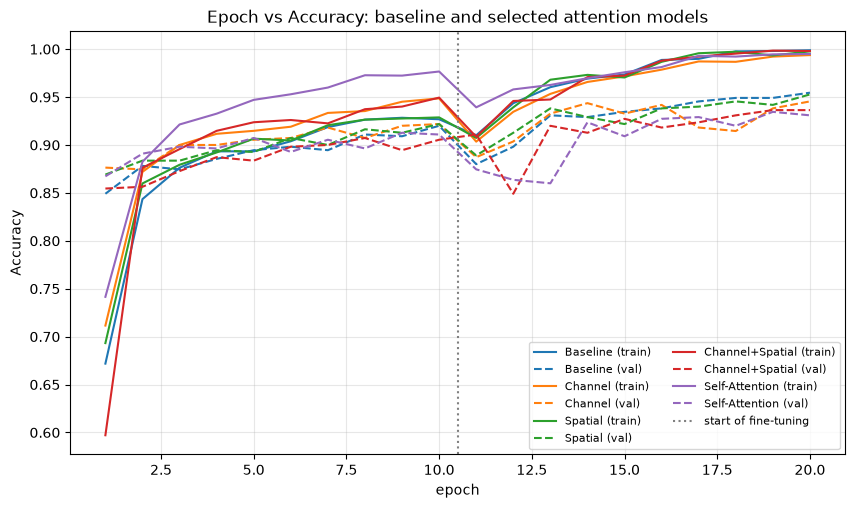

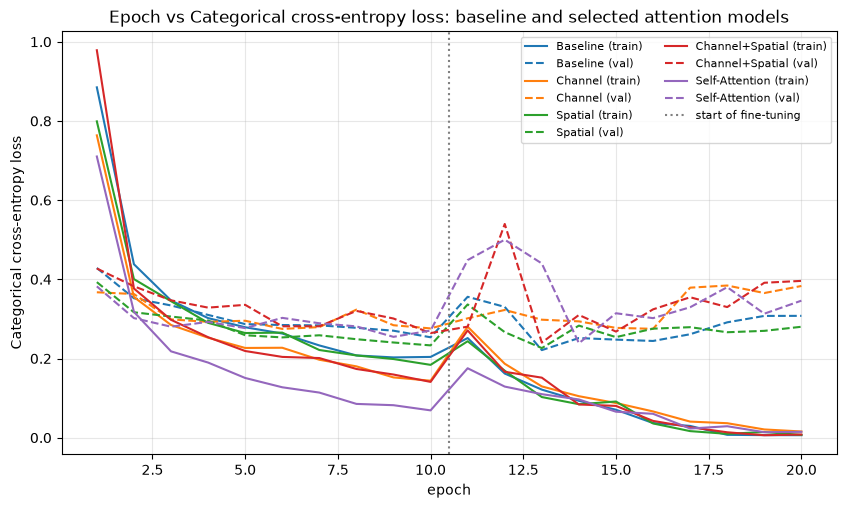

In [33]:
CURVE_MODELS = {"Baseline": "A0_Baseline", "Channel": "A1_Channel_P3", "Spatial": "A2_Spatial_P3",
                "Channel+Spatial": "A3_ChSp_P3", "Self-Attention": "A4_Self_P3"}

def plot_curves(models, metric, fname, ylabel):
    fig, ax = plt.subplots(figsize=(10, 5.5)); col = plt.cm.tab10.colors; pb = None
    for i, (lab, n) in enumerate(models.items()):
        r = RESULTS.get(resolve(n))
        if r is None: continue
        h = r["history"]; ep = np.arange(1, len(h[metric]) + 1)
        ax.plot(ep, h[metric], color=col[i], label=f"{lab} (train)")
        ax.plot(ep, h["val_" + metric], "--", color=col[i], label=f"{lab} (val)")
        pb = r["phase_boundary"]
    if pb is not None: ax.axvline(pb + 0.5, color="gray", ls=":", label="start of fine-tuning")
    ax.set_xlabel("epoch"); ax.set_ylabel(ylabel); ax.grid(alpha=.3); ax.legend(ncol=2, fontsize=8)
    ax.set_title(f"Epoch vs {ylabel}: baseline and selected attention models")
    save_fig(fname); plt.show()

plot_curves(CURVE_MODELS, "accuracy", "curves_accuracy", "Accuracy")
plot_curves(CURVE_MODELS, "loss", "curves_loss", "Categorical cross-entropy loss")

**Convergence numbers instead of impressions.** For the same models: epoch at which validation accuracy first reaches 90 %, final train–validation accuracy gap, how jumpy the validation curve is over the last 5 epochs (std), and the epoch whose weights were kept.

In [34]:
def convergence_table(models, thr=0.90):
    rows = []
    for lab, n in models.items():
        r = RESULTS.get(resolve(n))
        if r is None: continue
        h = r["history"]; va = np.array(h["val_accuracy"]); tr = np.array(h["accuracy"])
        hit = np.where(va >= thr)[0]
        rows.append({"Model": lab, f"epoch val-acc ≥ {thr:.0%}": int(hit[0] + 1) if len(hit) else None,
                     "final train acc": tr[-1], "final val acc": va[-1], "train–val gap": tr[-1] - va[-1],
                     "val-acc std (last 5)": va[-5:].std(), "val-loss min": min(h["val_loss"]), "kept epoch": r["best_epoch"]})
    return pd.DataFrame(rows)
display(convergence_table(CURVE_MODELS).round(4))

,Model,epoch val-acc ≥ 90%,final train acc,final val acc,train–val gap,val-acc std (last 5),val-loss min,kept epoch
0,Baseline,8,0.9988,0.9545,0.0443,0.0054,0.2212,13
1,Channel,5,0.9938,0.9455,0.0483,0.0127,0.2747,6
2,Spatial,6,0.9977,0.9527,0.0449,0.0051,0.2263,13
3,Channel+Spatial,8,0.9981,0.9364,0.0617,0.0072,0.2402,13
4,Self-Attention,5,0.9949,0.9309,0.0640,0.0048,0.2386,14


### ✍️ Your analysis – curves
Does attention accelerate convergence? Smoother learning? Smaller train–val gap, over-fitting, or instability? Quote the numbers above and describe specific features of the curves.

## 11.3 / 11.4 Attention mechanism vs accuracy and vs macro-F1 (§24.3, §24.4)
Macro-F1 matters when class-wise performance is not uniform.

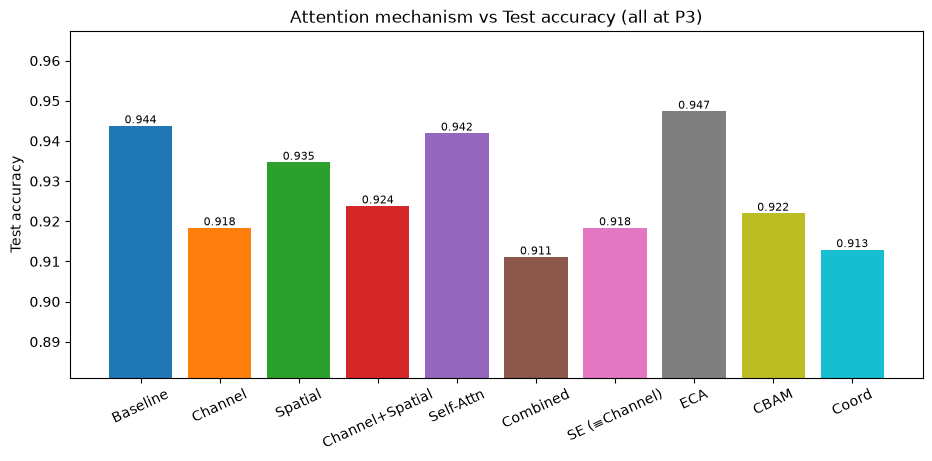

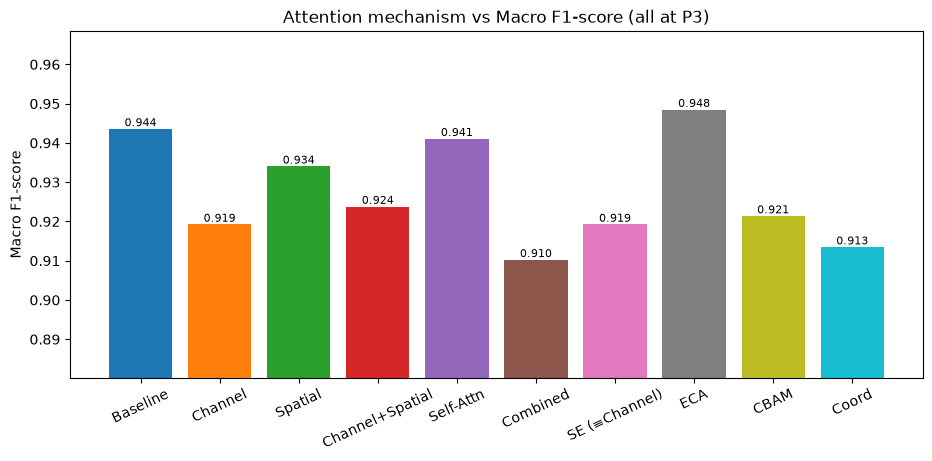

In [35]:
MECH = {"Baseline": "A0_Baseline", "Channel": "A1_Channel_P3", "Spatial": "A2_Spatial_P3",
        "Channel+Spatial": "A3_ChSp_P3", "Self-Attn": "A4_Self_P3", "Combined": "A5_Combined_P3",
        "SE (≡Channel)": "F0_SE_P3", "ECA": "F1_ECA_P3", "CBAM": "F2_CBAM_P3", "Coord": "F3_Coord_P3"}

def bar_metric(metric, ylabel, fname):
    labs = [l for l, n in MECH.items() if resolve(n) in RESULTS]
    vals = [RESULTS[resolve(MECH[l])][metric] for l in labs]
    fig, ax = plt.subplots(figsize=(11, 4.5))
    bars = ax.bar(labs, vals, color=plt.cm.tab10.colors[:len(labs)])
    for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    lo = min(vals) - 0.03; ax.set_ylim(max(0, lo), min(1.0, max(vals) + 0.02))
    ax.set_ylabel(ylabel); ax.set_title(f"Attention mechanism vs {ylabel} (all at P3)"); plt.xticks(rotation=25)
    save_fig(fname); plt.show()

bar_metric("accuracy", "Test accuracy", "bar_accuracy")
bar_metric("f1", "Macro F1-score", "bar_macro_f1")

## 11.5 Accuracy vs model parameters (§24.5) and 11.6 Macro-F1 vs inference time (§24.6)
These show the **accuracy–complexity** and **F1–latency** trade-offs: is the extra cost buying meaningful performance?

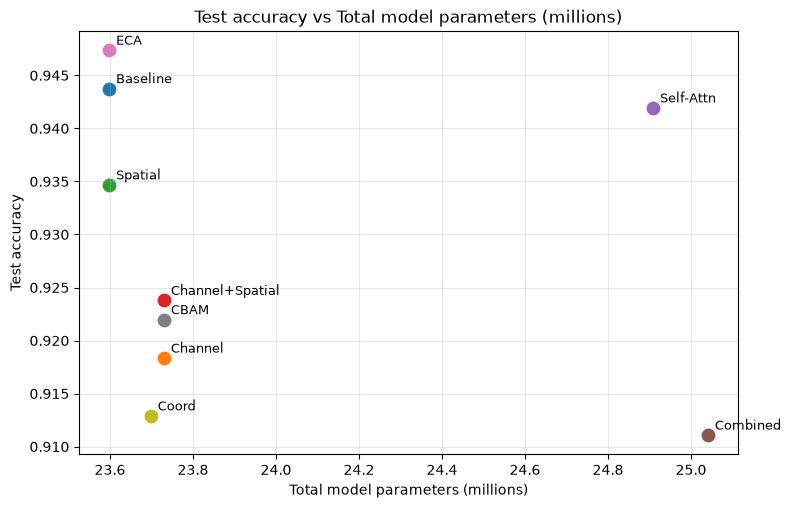

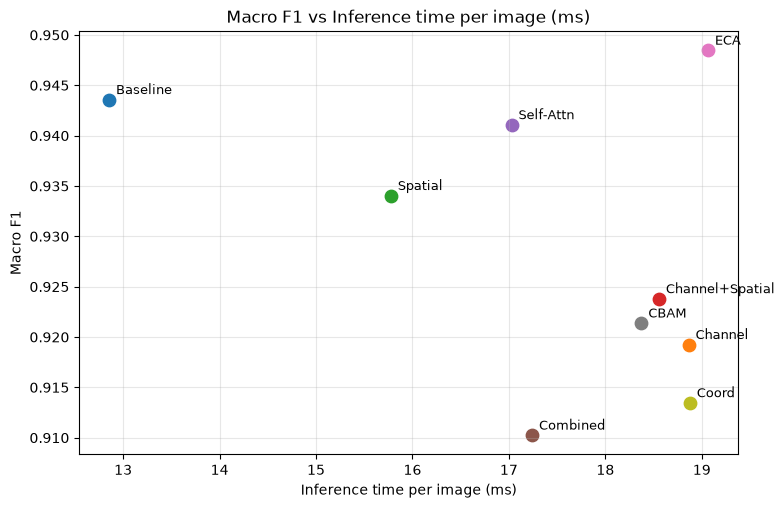

In [36]:
def scatter_tradeoff(xkey, ykey, xlabel, ylabel, fname, scale=1.0):
    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    for l, n in MECH.items():
        r = RESULTS.get(resolve(n))
        if r is None or l.startswith("SE"): continue
        ax.scatter(r[xkey] * scale, r[ykey], s=80); ax.annotate(l, (r[xkey] * scale, r[ykey]), xytext=(5, 4), textcoords="offset points", fontsize=9)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.grid(alpha=.3); ax.set_title(f"{ylabel} vs {xlabel}")
    save_fig(fname); plt.show()

scatter_tradeoff("total_params", "accuracy", "Total model parameters (millions)", "Test accuracy", "scatter_acc_vs_params", 1e-6)
scatter_tradeoff("inference_ms", "f1", "Inference time per image (ms)", "Macro F1", "scatter_f1_vs_time")

### ✍️ Your analysis – trade-offs
Which point is on the “efficient frontier” (high score, low cost)? Does the module with the most parameters give the highest accuracy? Does extra latency buy a meaningful F1 gain?

---
# Part 12 · Confusion-Matrix Analysis (§25)
A confusion matrix shows **which classes are mistaken for which**, something overall accuracy cannot reveal. We compare the baseline with the selected attention model (`SEL`; change it to whichever attention model you want to study, e.g. the best one in your tables).

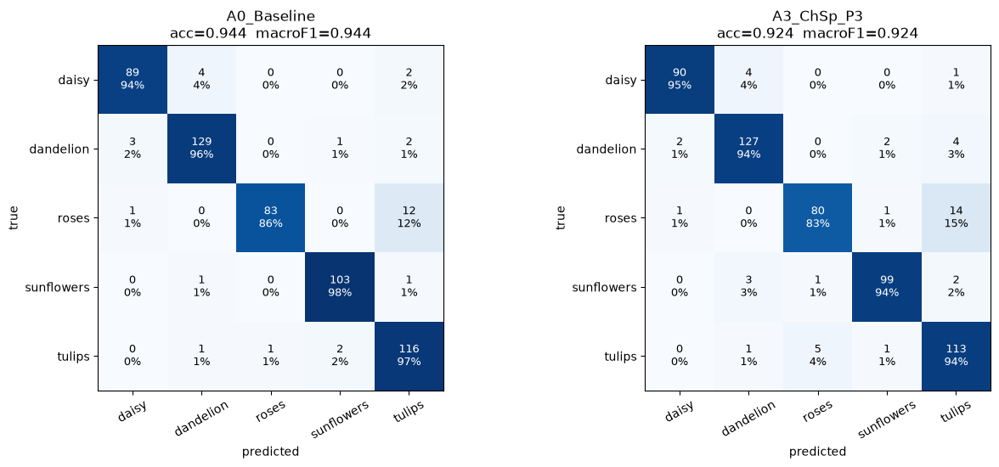

,class,recall base,recall attn,Δrecall,F1 base,F1 attn,ΔF1
0,daisy,0.937,0.947,0.011,0.947,0.957,0.011
1,dandelion,0.956,0.941,-0.015,0.956,0.941,-0.015
2,roses,0.865,0.833,-0.031,0.922,0.879,-0.043
3,sunflowers,0.981,0.943,-0.038,0.976,0.952,-0.024
4,tulips,0.967,0.942,-0.025,0.917,0.890,-0.027


Class that benefits most (ΔF1): daisy | class that loses most: roses
Most frequent confusions (baseline, true→predicted): [('roses', 'tulips', 12), ('daisy', 'dandelion', 4), ('dandelion', 'daisy', 3), ('daisy', 'tulips', 2)]
Most frequent confusions (attention, true→predicted): [('roses', 'tulips', 14), ('tulips', 'roses', 5), ('daisy', 'dandelion', 4), ('dandelion', 'tulips', 4)]


In [37]:
SEL = "A3_ChSp_P3"          # the "selected attention-based ResNet50"
def plot_confusions(names, fname="confusion_matrices"):
    fig, axes = plt.subplots(1, len(names), figsize=(6.6 * len(names), 5.6))
    for ax, n in zip(np.atleast_1d(axes), names):
        cm = np.array(RESULTS[resolve(n)]["confusion"]); pct = cm / cm.sum(1, keepdims=True)
        ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                ax.text(j, i, f"{cm[i, j]}\n{pct[i, j]:.0%}", ha="center", va="center", fontsize=9,
                        color="white" if pct[i, j] > .5 else "black")
        ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30); ax.set_yticks(range(NUM_CLASSES))
        ax.set_yticklabels(CLASS_NAMES); ax.set_xlabel("predicted"); ax.set_ylabel("true")
        ax.set_title(f"{n}\nacc={RESULTS[resolve(n)]['accuracy']:.3f}  macroF1={RESULTS[resolve(n)]['f1']:.3f}")
    plt.tight_layout(); save_fig(fname); plt.show()

plot_confusions(["A0_Baseline", SEL])

def confusion_analysis(base_name, att_name):
    cb, ca = (np.array(RESULTS[resolve(n)]["confusion"]) for n in (base_name, att_name))
    rb, ra = cb.diagonal() / cb.sum(1), ca.diagonal() / ca.sum(1)
    fb, fa = RESULTS[resolve(base_name)]["f1_per_class"], RESULTS[resolve(att_name)]["f1_per_class"]
    df = pd.DataFrame({"class": CLASS_NAMES, "recall base": rb, "recall attn": ra, "Δrecall": ra - rb,
                       "F1 base": fb, "F1 attn": fa, "ΔF1": np.array(fa) - np.array(fb)}).round(3)
    display(df)
    print("Class that benefits most (ΔF1):", df.loc[df["ΔF1"].idxmax(), "class"], "| class that loses most:", df.loc[df["ΔF1"].idxmin(), "class"])
    for tag, cm in (("baseline", cb), ("attention", ca)):
        off = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j])) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
        print(f"Most frequent confusions ({tag}, true→predicted):", sorted(off, key=lambda t: -t[2])[:4])

confusion_analysis("A0_Baseline", SEL)

### ✍️ Your analysis – confusion matrices
Which classes are classified best? Which pairs are confused (roses↔tulips? daisy↔dandelion?). Which class benefits most from attention? Is the overall improvement spread over all classes or concentrated in one? With so few errors per cell, be careful to talk about *counts*, not just percentages.

---
# Part 13 · Qualitative Analysis (§26 – §32)

Accuracy says *how well*; it does not say **where the network finds its evidence**. We therefore examine two fundamentally different things:

| | **Internal attention** | **Grad-CAM (post-hoc)** |
|---|---|---|
| Computed | during the forward pass, by the module itself | after prediction, using gradients |
| Depends on class? | no (same map for any class) | yes (class-specific) |
| Changes the prediction? | yes (it re-weights features) | no |
| Exists for baseline? | no | yes |

### Grad-CAM (§27)
For a chosen class score `y^c`, with feature maps `A^k` of the last feature layer: $\alpha_k^c=\frac1{HW}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}},\;\; L^c=\text{ReLU}\big(\sum_k\alpha_k^c A^k\big)$, resized to 224×224 and overlaid. We use the tensor that feeds the global-average-pooling layer (so any attention at P4 is included) and the *pre-softmax* score, as in the original paper.

**Rule for writing observations:** never write “Model A's Grad-CAM is better”. Describe visible evidence (e.g. “the baseline activates petals *and* surrounding leaves; the attention model concentrates on the petal region and is weaker over the background”) and base it on **several** images.

In [38]:
LOADED, _EXT, _GM = {}, {}, {}

def get_model(name):
    name = resolve(name)
    if name not in LOADED:
        m, _ = build_model(EXPERIMENTS[name], name=name, verbose=False)
        m.load_weights(os.path.join(OUT_DIR, f"{name}.weights.h5")); LOADED[name] = m
    return LOADED[name]

def prep_img(img):
    return preprocess_input(img.astype("float32")[None].copy())

def get_attention_layer(model, pos):
    c = [l for l in model.layers if l.name.startswith("att_") and l.name.endswith("_" + pos)]
    return c[0] if c else None

def _extractor(model, key, outs):
    k = (id(model), key)
    if k not in _EXT: _EXT[k] = keras.Model(model.input, outs)
    return _EXT[k]

def attention_maps(name, pos, img):
    """Internal attention maps (numpy) of the attention module at `pos`, for one uint8 image."""
    model = get_model(name); att = get_attention_layer(model, pos)
    feat = _extractor(model, ("in", pos), att.input)(prep_img(img), training=False)
    return {k: v.numpy() for k, v in att.get_maps(feat).items()}

def feature_before_after(name, pos, img):
    model = get_model(name); att = get_attention_layer(model, pos)
    fi, fo = _extractor(model, ("io", pos), [att.input, att.output])(prep_img(img), training=False)
    return fi.numpy()[0], fo.numpy()[0]

def gradcam(model, img, class_idx=None):
    """Grad-CAM w.r.t. the tensor feeding GAP and the pre-softmax class score. Returns (cam224, pred, probs)."""
    k = id(model)
    if k not in _GM:
        _GM[k] = keras.Model(model.input, [model.get_layer("gap").input, model.get_layer("logits").output])
    x = tf.convert_to_tensor(prep_img(img))
    with tf.GradientTape() as tape:
        conv, logits = _GM[k](x, training=False)
        c = int(tf.argmax(logits[0])) if class_idx is None else int(class_idx)
        score = logits[:, c]
    grads = tape.gradient(score, conv)
    alpha = tf.reduce_mean(grads, axis=(1, 2))                               # (1, C)  importance coefficients
    cam = tf.nn.relu(tf.reduce_sum(alpha[:, None, None, :] * conv, -1))[0]   # (h, w)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE))[..., 0].numpy()
    return cam, int(tf.argmax(logits[0])), tf.nn.softmax(logits[0]).numpy()

def resize_map(m):
    m = tf.image.resize(np.asarray(m, dtype="float32")[..., None], (IMG_SIZE, IMG_SIZE))[..., 0].numpy()
    return (m - m.min()) / (m.max() - m.min() + 1e-8)

def overlay(img, heat, alpha=0.45):
    return np.clip((1 - alpha) * img / 255.0 + alpha * plt.get_cmap("jet")(heat)[..., :3], 0, 1)

def show(ax, im, title, cmap=None):
    ax.imshow(im, cmap=cmap, vmin=0 if cmap else None, vmax=1 if cmap else None); ax.set_title(title, fontsize=9); ax.axis("off")

pred_of = lambda n: np.array(RESULTS[resolve(n)]["y_pred"])
print("helpers ready")

helpers ready


### Choosing test images
The sheet asks for **≥ 3 correctly and ≥ 2 incorrectly classified** images and warns against conclusions from one image. We select images automatically (reproducibly), and you can override `GOOD_IDX` / `BAD_IDX` with your own favourites.

In [39]:
rs = np.random.RandomState(7)
_have = [n for n in ["A0_Baseline", "A1_Channel_P3", "A2_Spatial_P3", SEL, "A4_Self_P3"] if resolve(n) in RESULTS]
ok_all = np.where(np.all([pred_of(n) == y_te for n in _have], axis=0))[0]
bad_sel = np.where(pred_of(SEL) != y_te)[0]
bad_base = np.where(pred_of("A0_Baseline") != y_te)[0]
bad_pool = bad_sel if len(bad_sel) >= 2 else bad_base
ok_pool = ok_all if len(ok_all) >= 3 else np.arange(len(y_te))     # fallback if too few images are right
GOOD_IDX = sorted(rs.choice(ok_pool, 3, replace=False).tolist())
bad_pool = bad_pool if len(bad_pool) else np.arange(len(y_te))
BAD_IDX = sorted(rs.choice(bad_pool, min(2, len(bad_pool)), replace=False).tolist())
print("correct images:", GOOD_IDX, "| incorrect images:", BAD_IDX)
for i in GOOD_IDX + BAD_IDX:
    print(f"  test[{i}] true={CLASS_NAMES[y_te[i]]:10s} baseline→{CLASS_NAMES[pred_of('A0_Baseline')[i]]:10s} {SEL}→{CLASS_NAMES[pred_of(SEL)[i]]}")

correct images: [13, 440, 458] | incorrect images: [222, 530]
  test[13] true=dandelion  baseline→dandelion  A3_ChSp_P3→dandelion
  test[440] true=tulips     baseline→tulips     A3_ChSp_P3→tulips
  test[458] true=daisy      baseline→daisy      A3_ChSp_P3→daisy
  test[222] true=roses      baseline→tulips     A3_ChSp_P3→tulips
  test[530] true=dandelion  baseline→dandelion  A3_ChSp_P3→tulips


## 13.1 Feature maps before and after attention (required viz #5 and #10)
The **channel-mean activation** and a few individual channels, just before and just after the attention module (P3), for the selected model. Dimensions are identical by construction; what changes is *which values are amplified or suppressed*.

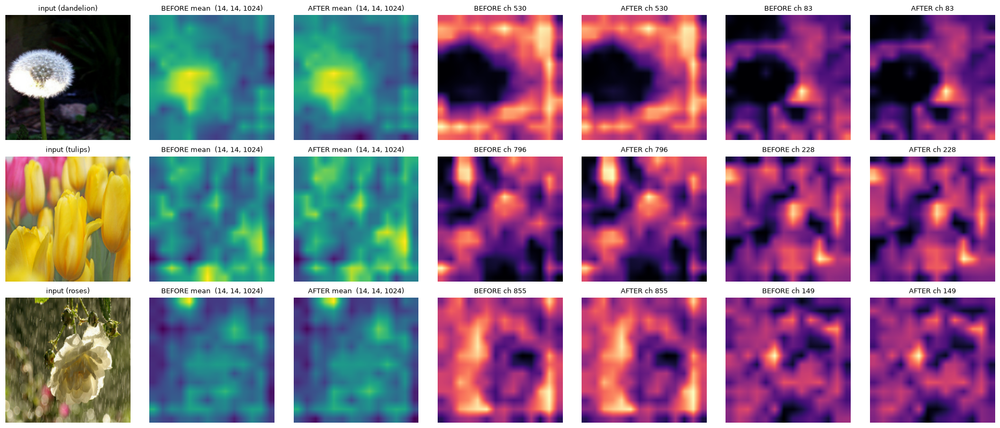

In [40]:
def plot_feature_before_after(name, pos, idxs, fname="feature_maps_before_after"):
    fig, axes = plt.subplots(len(idxs), 7, figsize=(19, 2.7 * len(idxs)))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(idxs):
        img = X_te[i]; fi, fo = feature_before_after(name, pos, img)
        ch = np.argsort(-fi.mean((0, 1)))[:2]                     # two most active input channels
        show(axes[r, 0], img / 255.0, f"input ({CLASS_NAMES[y_te[i]]})")
        show(axes[r, 1], resize_map(fi.mean(-1)), f"BEFORE mean  {fi.shape}", "viridis")
        show(axes[r, 2], resize_map(fo.mean(-1)), f"AFTER mean  {fo.shape}", "viridis")
        for k, c in enumerate(ch):
            show(axes[r, 3 + 2 * k], resize_map(fi[..., c]), f"BEFORE ch {c}", "magma")
            show(axes[r, 4 + 2 * k], resize_map(fo[..., c]), f"AFTER ch {c}", "magma")
    plt.tight_layout(); save_fig(fname); plt.show()
plot_feature_before_after(SEL, "P3", GOOD_IDX[:2] + BAD_IDX[:1])

## 13.2 Channel-attention weights (§28.1, required viz #6)
`M_c(F) = [m_1 … m_C]`. With C = 1024 we show the **top-K = 20** channels for several images and quantify: do a few channels dominate? Do many contribute equally? Do the weights change from image to image?

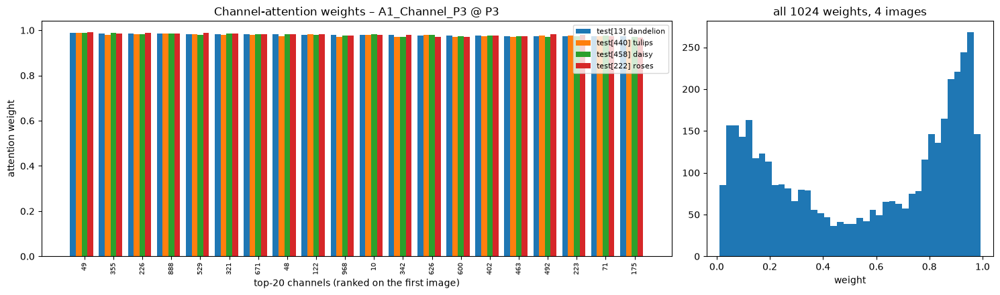

mean weight=0.550  std=0.335  min=0.011  max=0.991
fraction of channels with weight > 0.5: 56.0% | weight share of top-20 channels: 3.5% (uniform would be 2.0%)
correlation of weight vectors between images (≈1 ⇒ nearly input-independent):
 [[1.    0.991 0.998 0.994]
 [0.991 1.    0.993 0.995]
 [0.998 0.993 1.    0.994]
 [0.994 0.995 0.994 1.   ]]


In [41]:
def plot_channel_weights(name, pos, idxs, K=20, fname="channel_attention_weights"):
    W = np.stack([attention_maps(name, pos, X_te[i])["channel_weights"][0] for i in idxs])      # (n_img, C)
    order = np.argsort(-W[0])[:K]
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
    wd = 0.8 / len(idxs)
    for j, i in enumerate(idxs):
        axes[0].bar(np.arange(K) + j * wd, W[j][order], wd, label=f"test[{i}] {CLASS_NAMES[y_te[i]]}")
    axes[0].set_xticks(np.arange(K) + 0.4); axes[0].set_xticklabels(order, rotation=90, fontsize=7)
    axes[0].set_xlabel(f"top-{K} channels (ranked on the first image)"); axes[0].set_ylabel("attention weight"); axes[0].legend(fontsize=8)
    axes[0].set_title(f"Channel-attention weights – {name} @ {pos}")
    axes[1].hist(W.ravel(), bins=40, color="tab:blue"); axes[1].set_title(f"all {W.shape[1]} weights, {len(idxs)} images"); axes[1].set_xlabel("weight")
    plt.tight_layout(); save_fig(fname); plt.show()
    c = np.corrcoef(W) if len(idxs) > 1 else np.array([[1.0]])
    print(f"mean weight={W.mean():.3f}  std={W.std():.3f}  min={W.min():.3f}  max={W.max():.3f}")
    print(f"fraction of channels with weight > 0.5: {(W > 0.5).mean():.1%} | weight share of top-{K} channels: {np.sort(W[0])[-K:].sum()/W[0].sum():.1%} "
          f"(uniform would be {K/W.shape[1]:.1%})")
    print("correlation of weight vectors between images (≈1 ⇒ nearly input-independent):\n", np.round(c, 3))
plot_channel_weights("A1_Channel_P3", "P3", GOOD_IDX + BAD_IDX[:1])

## 13.3 Spatial-attention maps and overlays (§28.2, required viz #7, #8)
`M_s(F) ∈ ℝ^{H×W}` is resized to 224×224 and overlaid. Panels: **input · spatial attention map · overlay**. (Warm colours = high attention. Note the map is *class-agnostic*.)

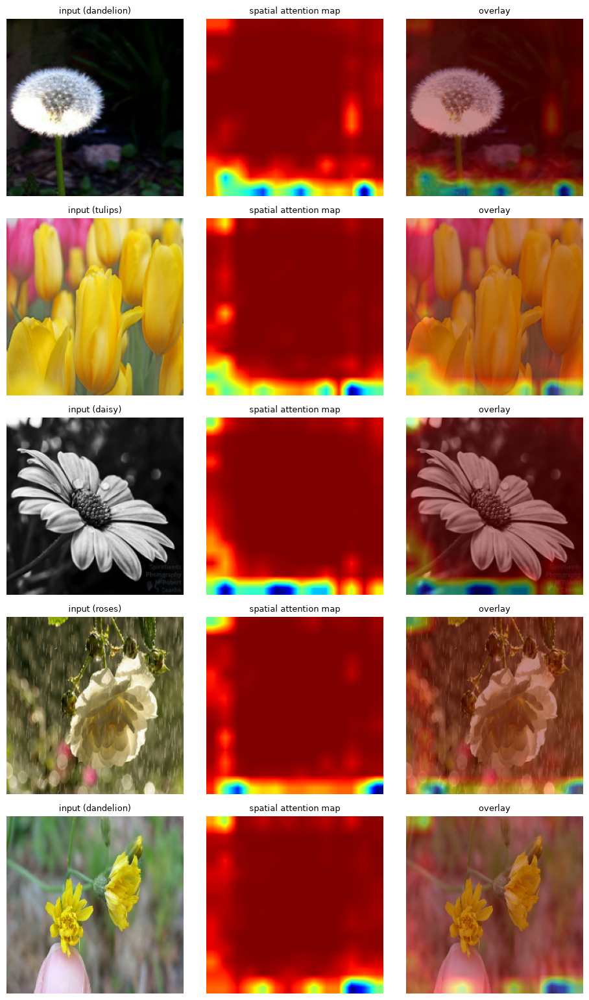

In [42]:
def plot_spatial(name, pos, idxs, fname="spatial_attention_overlay"):
    fig, axes = plt.subplots(len(idxs), 3, figsize=(9.5, 3.1 * len(idxs))); axes = np.atleast_2d(axes)
    for r, i in enumerate(idxs):
        m = resize_map(attention_maps(name, pos, X_te[i])["spatial_map"][0]); img = X_te[i]
        show(axes[r, 0], img / 255.0, f"input ({CLASS_NAMES[y_te[i]]})")
        show(axes[r, 1], m, "spatial attention map", "jet"); show(axes[r, 2], overlay(img, m), "overlay")
    plt.tight_layout(); save_fig(fname); plt.show()
plot_spatial(SEL, "P3", GOOD_IDX + BAD_IDX)

## 13.4 Self-attention response (§28.3, required viz #9)
For the self-attention model (A4) we show: a **selected query** location (and the keys it attends to), the **mean** attention over queries, the **max** over queries, and the aggregated **response** `mean|Y|`. We also measure **how distant regions interact**: the share of attention mass placed on keys at each distance from the query, compared with what *uniform* attention would give.

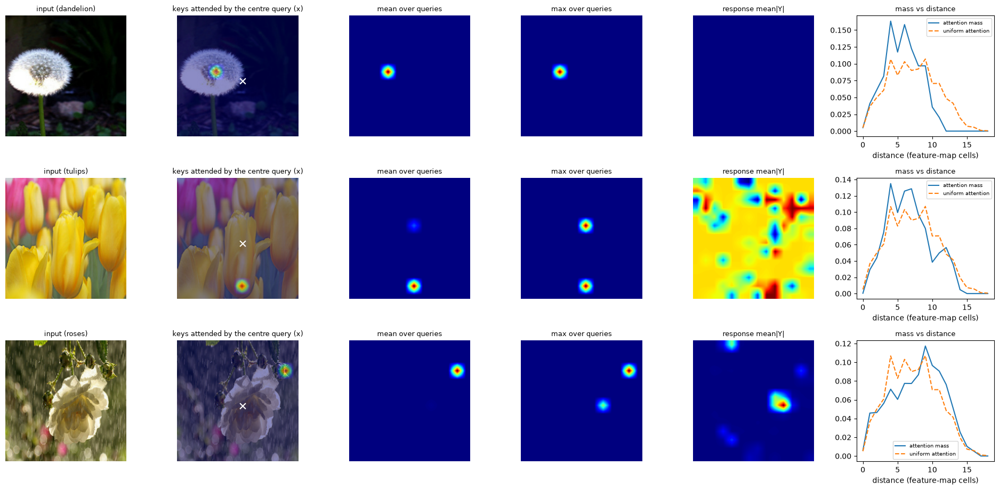

learned γ = 0.0664  (γ≈0 would mean the network barely uses self-attention)
attention mass relative to uniform at distance 0 (itself) / 1 / largest (per image): [(np.float64(1.0), np.float64(1.12), np.float64(0.0)), (np.float64(0.07), np.float64(0.8), np.float64(0.0)), (np.float64(1.19), np.float64(1.25), np.float64(0.0))]


In [43]:
def distance_profile(A, H, W):
    ys, xs = np.divmod(np.arange(H * W), W); co = np.stack([ys, xs], 1)
    D = np.round(np.sqrt(((co[:, None] - co[None]) ** 2).sum(-1))).astype(int)
    mass, uni = np.zeros(D.max() + 1), np.zeros(D.max() + 1)
    for d in range(D.max() + 1):
        msk = D == d; mass[d] = (A * msk).sum() / A.shape[0]; uni[d] = msk.mean()
    return mass, uni

def plot_self_attention(name, pos, idxs, fname="self_attention_response"):
    H, W, _ = POS_SHAPES[pos]; rows = len(idxs)
    fig, axes = plt.subplots(rows, 6, figsize=(19, 3.1 * rows)); axes = np.atleast_2d(axes)
    prof = []
    for r, i in enumerate(idxs):
        img = X_te[i]; m = attention_maps(name, pos, img); A = m["attention_matrix"][0]            # (N, N)
        q = (H // 2) * W + W // 2                                                                    # centre query
        show(axes[r, 0], img / 255.0, f"input ({CLASS_NAMES[y_te[i]]})")
        qimg = overlay(img, resize_map(A[q].reshape(H, W)))
        axes[r, 1].imshow(qimg); axes[r, 1].scatter([(q % W + .5) * IMG_SIZE / W], [(q // W + .5) * IMG_SIZE / H], c="white", s=60, marker="x")
        axes[r, 1].set_title("keys attended by the centre query (x)", fontsize=9); axes[r, 1].axis("off")
        show(axes[r, 2], resize_map(A.mean(0).reshape(H, W)), "mean over queries", "jet")
        show(axes[r, 3], resize_map(A.max(0).reshape(H, W)), "max over queries", "jet")
        show(axes[r, 4], resize_map(m["self_attention_response"][0]), "response mean|Y|", "jet")
        mass, uni = distance_profile(A, H, W); prof.append(mass / uni.clip(1e-9))
        axes[r, 5].plot(mass, label="attention mass"); axes[r, 5].plot(uni, "--", label="uniform attention"); axes[r, 5].set_title("mass vs distance", fontsize=9)
        axes[r, 5].set_xlabel("distance (feature-map cells)"); axes[r, 5].legend(fontsize=7)
    plt.tight_layout(); save_fig(fname); plt.show()
    gam = float(keras.ops.convert_to_numpy(get_attention_layer(get_model(name), pos).gamma))
    print(f"learned γ = {gam:.4f}  (γ≈0 would mean the network barely uses self-attention)")
    print("attention mass relative to uniform at distance 0 (itself) / 1 / largest (per image):",
          [(round(p[0], 2), round(p[1], 2), round(p[-1], 2)) for p in prof])
plot_self_attention("A4_Self_P3", "P3", GOOD_IDX[:2] + BAD_IDX[:1])

## 13.5 Attention maps at different depths: M_s at P2, P3, P4 (§29, required viz #13)
Same test image, spatial attention of the Channel→Spatial models inserted at P2 (B2), P3 (A3) and P4 (B4); P1 (B1) is added if trained. The sheet suggests, as *hypotheses to verify, not to assume*: P2 → edges/colours/fine structure; P3 → flower parts; P4 → large semantic flower regions.

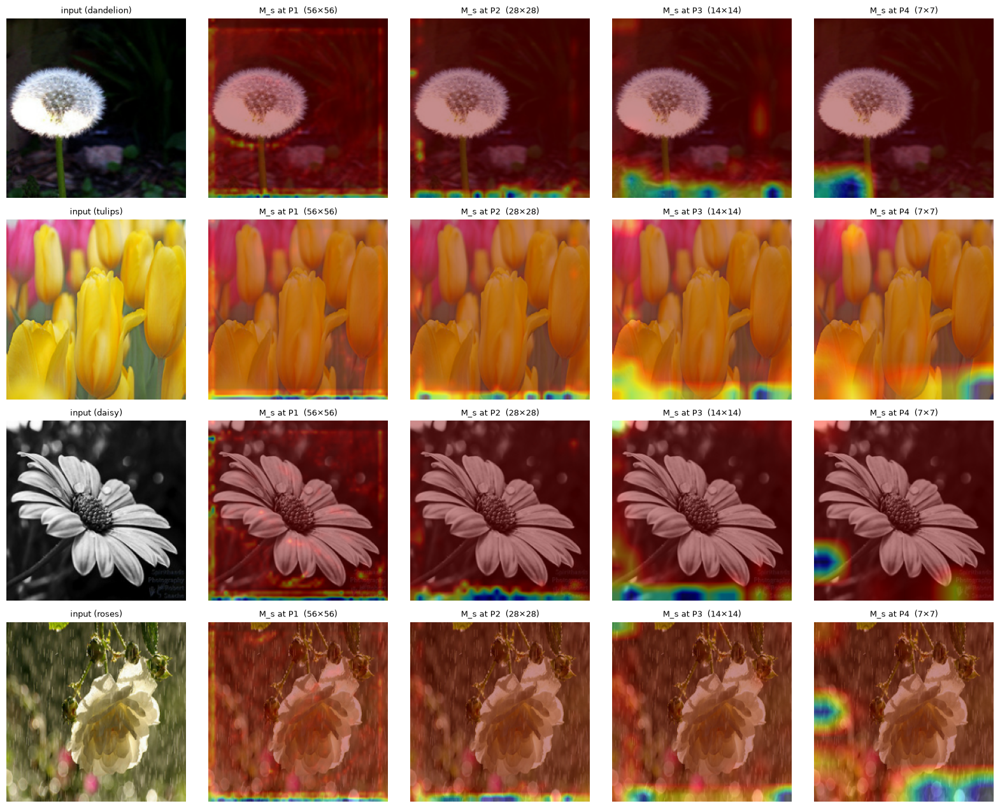

In [44]:
POS_MODELS = [("P1", "B1_ChSp_P1"), ("P2", "B2_ChSp_P2"), ("P3", "A3_ChSp_P3"), ("P4", "B4_ChSp_P4")]
def plot_position_maps(idxs, fname="attention_maps_P2_P3_P4"):
    avail = [(p, n) for p, n in POS_MODELS if n in RESULTS]
    fig, axes = plt.subplots(len(idxs), 1 + len(avail), figsize=(3.2 * (1 + len(avail)), 3.2 * len(idxs))); axes = np.atleast_2d(axes)
    for r, i in enumerate(idxs):
        show(axes[r, 0], X_te[i] / 255.0, f"input ({CLASS_NAMES[y_te[i]]})")
        for c, (p, n) in enumerate(avail, start=1):
            m = attention_maps(n, p, X_te[i])["spatial_map"][0]
            show(axes[r, c], overlay(X_te[i], resize_map(m)), f"M_s at {p}  ({m.shape[0]}×{m.shape[1]})")
    plt.tight_layout(); save_fig(fname); plt.show()
plot_position_maps(GOOD_IDX + BAD_IDX[:1])

## 13.6 Grad-CAM: baseline vs attention models (§27, §32, required viz #11, #12)
Layout recommended by the sheet for one image: **Input · Baseline Grad-CAM · Channel Grad-CAM · Spatial attention map · Channel+Spatial Grad-CAM** (we add the Self-attention response). Titles show `true / predicted`.

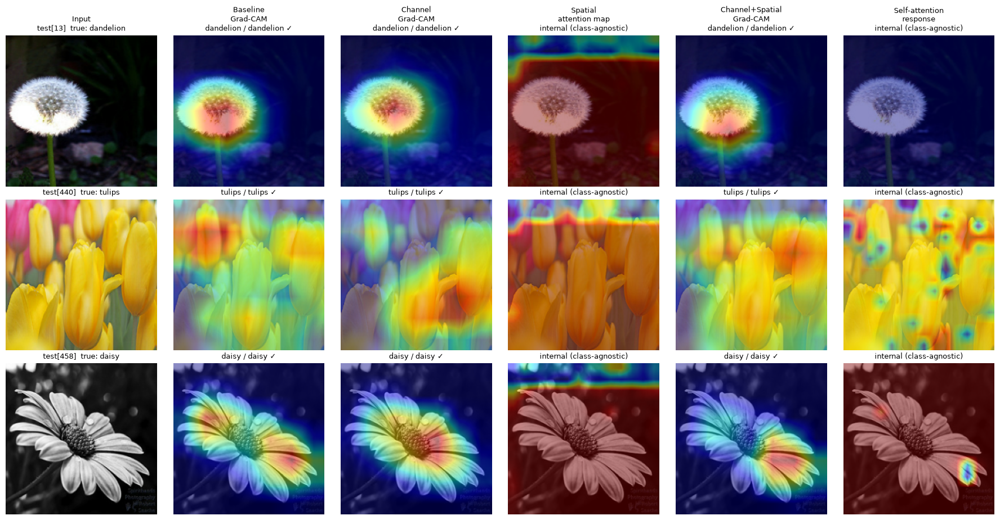

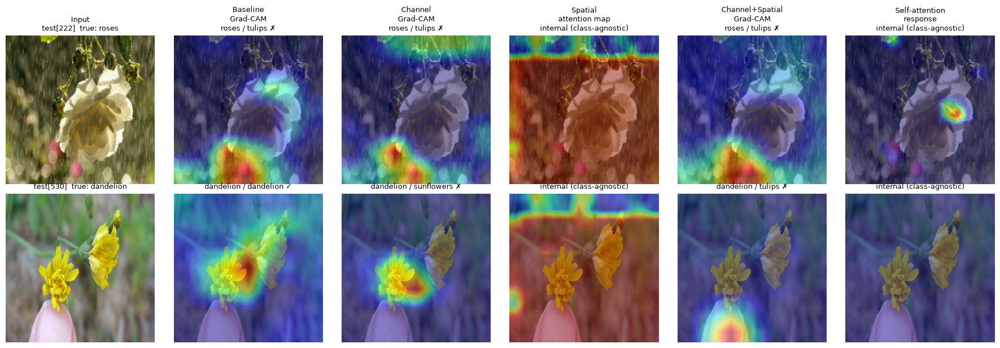

In [45]:
def qualitative_grid(idxs, fname):
    cols = ["Input", "Baseline\nGrad-CAM", "Channel\nGrad-CAM", "Spatial\nattention map", "Channel+Spatial\nGrad-CAM", "Self-attention\nresponse"]
    missing = [n for n in ("A0_Baseline", "A1_Channel_P3", "A2_Spatial_P3", SEL, "A4_Self_P3") if resolve(n) not in RESULTS]
    assert not missing, f"train these experiments first: {missing}"
    fig, axes = plt.subplots(len(idxs), 6, figsize=(18, 3.1 * len(idxs))); axes = np.atleast_2d(axes)
    for r, i in enumerate(idxs):
        img, t = X_te[i], CLASS_NAMES[y_te[i]]
        show(axes[r, 0], img / 255.0, f"test[{i}]  true: {t}")
        for c, n in ((1, "A0_Baseline"), (2, "A1_Channel_P3"), (4, SEL)):
            cam, pr, _ = gradcam(get_model(n), img)
            show(axes[r, c], overlay(img, cam), f"{t} / {CLASS_NAMES[pr]} {'✓' if pr == y_te[i] else '✗'}")
        show(axes[r, 3], overlay(img, resize_map(attention_maps("A2_Spatial_P3", "P3", img)["spatial_map"][0])), "internal (class-agnostic)")
        show(axes[r, 5], overlay(img, resize_map(attention_maps("A4_Self_P3", "P3", img)["self_attention_response"][0])), "internal (class-agnostic)")
    for c, name in enumerate(cols): axes[0, c].set_title(name + "\n" + axes[0, c].get_title(), fontsize=9)
    plt.tight_layout(); save_fig(fname); plt.show()

qualitative_grid(GOOD_IDX, "gradcam_baseline_vs_attention")           # 3 correctly classified images
qualitative_grid(BAD_IDX, "qualitative_incorrect_images")             # incorrectly classified images

**Extended comparison (§32, for the additional-attention study):** Input · Baseline · SE · ECA · CBAM · Self-Attention · Coordinate, all as Grad-CAM so that the methods are visualised in the same way.

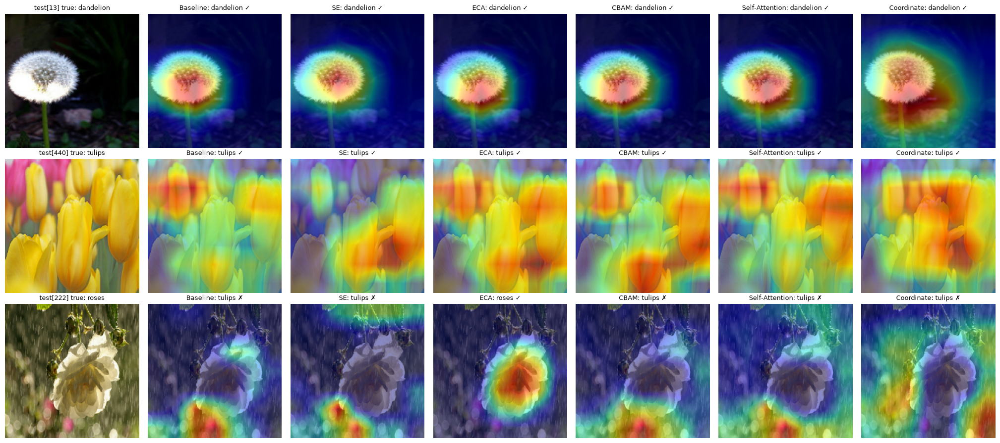

In [46]:
def extended_grid(idxs, fname="gradcam_extended_comparison"):
    models = [("Baseline", "A0_Baseline"), ("SE", "F0_SE_P3"), ("ECA", "F1_ECA_P3"), ("CBAM", "F2_CBAM_P3"),
              ("Self-Attention", "A4_Self_P3"), ("Coordinate", "F3_Coord_P3")]
    models = [(lab, n) for lab, n in models if resolve(n) in RESULTS]          # only the models you have trained
    fig, axes = plt.subplots(len(idxs), 1 + len(models), figsize=(2.9 * (1 + len(models)), 3.0 * len(idxs))); axes = np.atleast_2d(axes)
    for r, i in enumerate(idxs):
        show(axes[r, 0], X_te[i] / 255.0, f"test[{i}] true: {CLASS_NAMES[y_te[i]]}")
        for c, (lab, n) in enumerate(models, start=1):
            cam, pr, _ = gradcam(get_model(n), X_te[i])
            show(axes[r, c], overlay(X_te[i], cam), f"{lab}: {CLASS_NAMES[pr]} {'✓' if pr == y_te[i] else '✗'}")
    plt.tight_layout(); save_fig(fname); plt.show()
extended_grid(GOOD_IDX[:2] + BAD_IDX[:1])

## 13.7 From pictures to numbers: summary statistics over many images (§30.1, §40)
Single images can mislead, so we measure Grad-CAM over **many test images**:
* **coverage** – fraction of pixels with activation > 0.5 (smaller = more compact; larger = spread over the whole flower);
* **border share** – share of total activation in the outer 25 % frame of the image, relative to the share a uniform map would have (0.44). Values below 0.44 mean activation sits more centrally. *This is only a rough proxy for “background suppression”: flowers are not always centred, so interpret it together with the pictures.*

In [47]:
def cam_stats(cam):
    b = IMG_SIZE // 8; mask = np.ones_like(cam, bool); mask[b:-b, b:-b] = False
    return (cam > 0.5).mean(), cam[mask].sum() / (cam.sum() + 1e-8)

def cam_table(models, n_img=60, seed=3):
    ids = np.random.RandomState(seed).choice(len(y_te), n_img, replace=False); rows = []
    for lab, n in models.items():
        st = np.array([cam_stats(gradcam(get_model(n), X_te[i])[0]) for i in ids])
        rows.append({"Model": lab, "coverage mean": st[:, 0].mean(), "coverage std": st[:, 0].std(),
                     "border share mean": st[:, 1].mean(), "border share std": st[:, 1].std()})
    return pd.DataFrame(rows)
CAM_MODELS = {"Baseline": "A0_Baseline", "Channel": "A1_Channel_P3", "Spatial": "A2_Spatial_P3", "Channel+Spatial": SEL,
              "Self-Attention": "A4_Self_P3", "ECA": "F1_ECA_P3", "CBAM": "F2_CBAM_P3", "Coordinate": "F3_Coord_P3"}
display(cam_table({k: v for k, v in CAM_MODELS.items() if resolve(v) in RESULTS}).round(3))
print("uniform-map border share would be", round(1 - (0.75) ** 2, 3))

,Model,coverage mean,coverage std,border share mean,border share std
0,Baseline,0.220,0.104,0.193,0.117
1,Channel,0.213,0.125,0.233,0.142
2,Spatial,0.178,0.104,0.195,0.132
3,Channel+Spatial,0.199,0.126,0.192,0.114
4,Self-Attention,0.282,0.159,0.263,0.113
5,ECA,0.227,0.129,0.209,0.122
6,CBAM,0.185,0.103,0.207,0.145
7,Coordinate,0.372,0.163,0.232,0.085


uniform-map border share would be 0.438


### ✍️ Your analysis – qualitative (§27.1, §30.1)
Describe *visible evidence* for several images: Does the attention model focus more on the flower? Suppress background? Concentrate on petals / the flower centre? Activate leaves or background objects incorrectly? How do maps differ for **incorrect** predictions? How do shallow (P2) and deep (P4) attention differ? Is attention consistent across images? Do the quantitative numbers and the pictures agree?

*Remember:* an internal attention map is **not** an explanation of the final decision, whereas Grad-CAM is class-specific. Where they disagree, say so.

---
# Part 13b · Optional: robustness to random seed
A single training run per model is a *sample*. For the one or two most important comparisons, repeat with other seeds (same data split, only the training randomness changes) and report mean ± std. This is the most reliable way to decide whether a small gap is real. (Takes time; skip if short.)

In [48]:
RUN_MULTI_SEED = False
SEEDS = [1, 2]
if RUN_MULTI_SEED:
    for n in ["A0_Baseline", "A3_ChSp_P3"]:
        for s in SEEDS: run_experiment(n, seed=s)
    rows = []
    for n in ["A0_Baseline", "A3_ChSp_P3"]:
        accs = [RESULTS[n]["accuracy"]] + [RESULTS[f"{n}__seed{s}"]["accuracy"] for s in SEEDS]
        rows.append({"model": n, "mean acc": np.mean(accs), "std": np.std(accs), "runs": np.round(accs, 4).tolist()})
    display(pd.DataFrame(rows))

---
# Part 14 · Required-visualisation checklist (§31) and final analyses (§33)

The checklist verifies that all 14 required figures were produced and saved in `lab_outputs_mac/figures/`.

In [49]:
REQUIRED = {1: ("sample images from all five classes", "sample_images"),
            2: ("training & validation accuracy curves", "curves_accuracy"),
            3: ("training & validation loss curves", "curves_loss"),
            4: ("confusion matrix", "confusion_matrices"),
            5: ("feature map before attention", "feature_maps_before_after"),
            6: ("channel-attention weights", "channel_attention_weights"),
            7: ("spatial-attention heat-map", "spatial_attention_overlay"),
            8: ("spatial-attention overlay", "spatial_attention_overlay"),
            9: ("self-attention response", "self_attention_response"),
            10: ("feature map after attention", "feature_maps_before_after"),
            11: ("baseline Grad-CAM", "gradcam_baseline_vs_attention"),
            12: ("Grad-CAM of an attention model", "gradcam_baseline_vs_attention"),
            13: ("attention maps at P2, P3, P4", "attention_maps_P2_P3_P4"),
            14: ("graphical comparison of mechanisms", "bar_accuracy")}
for k, (desc, f) in REQUIRED.items():
    print(("✅" if os.path.exists(os.path.join(FIG_DIR, f + ".png")) else "❌ (run its cell)"), f"{k:2d}. {desc}  → {f}.png")

✅  1. sample images from all five classes  → sample_images.png
✅  2. training & validation accuracy curves  → curves_accuracy.png
✅  3. training & validation loss curves  → curves_loss.png
✅  4. confusion matrix  → confusion_matrices.png
✅  5. feature map before attention  → feature_maps_before_after.png
✅  6. channel-attention weights  → channel_attention_weights.png
✅  7. spatial-attention heat-map  → spatial_attention_overlay.png
✅  8. spatial-attention overlay  → spatial_attention_overlay.png
✅  9. self-attention response  → self_attention_response.png
✅ 10. feature map after attention  → feature_maps_before_after.png
✅ 11. baseline Grad-CAM  → gradcam_baseline_vs_attention.png
✅ 12. Grad-CAM of an attention model  → gradcam_baseline_vs_attention.png
✅ 13. attention maps at P2, P3, P4  → attention_maps_P2_P3_P4.png
✅ 14. graphical comparison of mechanisms  → bar_accuracy.png


## 14.1 Final three-part analysis (§33): quantitative + computational + qualitative

In [50]:
quant = results_table(main_rows + [("Coordinate (additional)", "P3", "F3_Coord_P3"), ("Combined C+S+SA", "P3", "A5_Combined_P3")])
print("QUANTITATIVE – Accuracy + Precision + Recall + Macro-F1");  display(quant[["Model", "Position", "Accuracy", "Precision", "Recall", "F1"]].round(4))
print("COMPUTATIONAL – Parameters + Inference time");               display(quant[["Model", "Position", "Params (total)", "Params (trainable, FT)", "Attn params", "Inference (ms/img)"]])
print("QUALITATIVE – see Part 13: Grad-CAM, attention maps, written interpretation.")
quant.to_csv(os.path.join(OUT_DIR, "final_summary_table.csv"), index=False)

QUANTITATIVE – Accuracy + Precision + Recall + Macro-F1


,Model,Position,Accuracy,Precision,Recall,F1
0,Baseline,–,0.9437,0.9489,0.9409,0.9436
1,Channel Attention,P3,0.9183,0.9218,0.9178,0.9192
2,Spatial Attention,P3,0.9347,0.9379,0.9312,0.9340
3,Channel+Spatial,P2,0.9510,0.9539,0.9488,0.9510
4,Channel+Spatial,P3,0.9238,0.9286,0.9212,0.9238
5,Channel+Spatial,P4,0.9310,0.9328,0.9309,0.9317
6,Self-Attention,P3,0.9419,0.9438,0.9392,0.9411
7,Additional Attention-1 (ECA),P3,0.9474,0.9498,0.9487,0.9485
8,Additional Attention-2 (CBAM),P3,0.9220,0.9257,0.9189,0.9214
9,Coordinate (additional),P3,0.9129,0.9202,0.9103,0.9135


COMPUTATIONAL – Parameters + Inference time


,Model,Position,Params (total),"Params (trainable, FT)",Attn params,Inference (ms/img)
0,Baseline,–,23597957,14963717,0,12.854442
1,Channel Attention,P3,23730117,15095877,132160,18.863584
2,Spatial Attention,P3,23598056,14963816,99,15.776172
3,Channel+Spatial,P2,23631368,14997128,33411,16.566119
4,Channel+Spatial,P3,23730216,15095976,132259,18.555971
5,Channel+Spatial,P4,24124520,15490280,526563,16.669675
6,Self-Attention,P3,24908678,16274438,1310721,17.027233
7,Additional Attention-1 (ECA),P3,23597962,14963722,5,19.063963
8,Additional Attention-2 (CBAM),P3,23730216,15095976,132259,18.373822
9,Coordinate (additional),P3,23698469,15064165,100512,18.876435


QUALITATIVE – see Part 13: Grad-CAM, attention maps, written interpretation.


## 14.2 Observations to record (§38)
Item 1 (input/output dimensions of each attention module), items 2–12 and 13 are exported below; items 14–18 (channel weights, spatial maps, self-attention responses, Grad-CAM, position maps) are the figures of Part 13.

In [51]:
shape_rows = []
for n, spec in EXPERIMENTS.items():
    for pos, (kind, kw) in spec.items():
        shp = POS_SHAPES[pos]; shape_rows.append({"experiment": n, "position": pos, "attention": kind, "input shape": shp, "output shape": shp})
shape_df = pd.DataFrame(shape_rows); display(shape_df)

obs = pd.DataFrame([{"experiment": k, "train acc (final)": v["train_acc_final"], "val acc (best)": v["val_acc_best"],
                     "test acc": v["accuracy"], "train loss (final)": v["history"]["loss"][-1], "val loss (final)": v["history"]["val_loss"][-1],
                     "test loss": v["test_loss"], "macro precision": v["precision"], "macro recall": v["recall"], "macro F1": v["f1"],
                     "trainable params (FT)": v["trainable_params_ft"], "total params": v["total_params"],
                     "inference ms/img": v["inference_ms"], "train time (min)": v["train_time_s"] / 60} for k, v in RESULTS.items()])
display(obs.round(4)); obs.to_csv(os.path.join(OUT_DIR, "observations_table.csv"), index=False); shape_df.to_csv(os.path.join(OUT_DIR, "attention_shapes.csv"), index=False)

,experiment,position,attention,input shape,output shape
0,A1_Channel_P3,P3,channel,"(14, 14, 1024)","(14, 14, 1024)"
1,A2_Spatial_P3,P3,spatial,"(14, 14, 1024)","(14, 14, 1024)"
2,A3_ChSp_P3,P3,cs,"(14, 14, 1024)","(14, 14, 1024)"
3,A4_Self_P3,P3,self,"(14, 14, 1024)","(14, 14, 1024)"
4,A5_Combined_P3,P3,combined,"(14, 14, 1024)","(14, 14, 1024)"
5,B1_ChSp_P1,P1,cs,"(56, 56, 256)","(56, 56, 256)"
6,B2_ChSp_P2,P2,cs,"(28, 28, 512)","(28, 28, 512)"
7,B4_ChSp_P4,P4,cs,"(7, 7, 2048)","(7, 7, 2048)"
8,C3_ChSp_P3P4,P3,cs,"(14, 14, 1024)","(14, 14, 1024)"
9,C3_ChSp_P3P4,P4,cs,"(7, 7, 2048)","(7, 7, 2048)"


,experiment,train acc (final),val acc (best),test acc,train loss (final),val loss (final),test loss,macro precision,macro recall,macro F1,trainable params (FT),total params,inference ms/img,train time (min)
0,A0_Baseline,0.9988,0.9545,0.9437,0.0063,0.3077,0.1915,0.9489,0.9409,0.9436,14963717,23597957,12.8544,13.0765
1,A1_Channel_P3,0.9938,0.9455,0.9183,0.0157,0.3832,0.2331,0.9218,0.9178,0.9192,15095877,23730117,18.8636,20.5563
2,A2_Spatial_P3,0.9977,0.9527,0.9347,0.0069,0.2802,0.1771,0.9379,0.9312,0.9340,14963816,23598056,15.7762,20.2577
3,A3_ChSp_P3,0.9981,0.9364,0.9238,0.0080,0.3961,0.2060,0.9286,0.9212,0.9238,15095976,23730216,18.5560,20.6076
4,B2_ChSp_P2,0.9996,0.9418,0.9510,0.0040,0.2721,0.2046,0.9539,0.9488,0.9510,14997128,23631368,16.5661,25.6046
5,B4_ChSp_P4,0.9992,0.9455,0.9310,0.0037,0.3545,0.2143,0.9328,0.9309,0.9317,15490280,24124520,16.6697,19.3467
6,A4_Self_P3,0.9949,0.9345,0.9419,0.0148,0.3461,0.1952,0.9438,0.9392,0.9411,16274438,24908678,17.0272,22.0174
7,A5_Combined_P3,0.9946,0.9455,0.9111,0.0144,0.3806,0.2710,0.9120,0.9104,0.9102,16406697,25040937,17.2404,23.3971
8,B1_ChSp_P1,0.9988,0.9364,0.9093,0.0061,0.4588,0.2506,0.9141,0.9068,0.9079,14972280,23606520,16.8502,30.3731
9,C3_ChSp_P3P4,0.9977,0.9455,0.9383,0.0054,0.3574,0.1922,0.9374,0.9392,0.9382,15622539,24256779,17.4843,22.0221


---
# Part 15 · The 35 Questions (§37)

**Conceptual questions** are answered below so that you can study them. **Result-dependent questions are marked ✍️**: answer them yourself from *your* tables and figures (hints given). Rewrite the conceptual answers in your own words in the report.

**1. Purpose of residual connections?** A block computes `y = F(x) + x`. The identity path gives gradients a direct route to early layers (mitigating vanishing gradients) and lets each block learn only a *correction* to its input, which makes very deep networks trainable and easier to optimise.

**2. conv2_x vs conv5_x?** conv2_x is the first stage after the stem: 56×56×256, low-level textures/boundaries, small receptive field. conv5_x is the last: 7×7×2048, high-level semantic, class-discriminative features, very large receptive field.

**3. Why does resolution fall with depth?** Strided convolution/pooling (stem, first block of conv3–5) enlarge the receptive field, aggregate local evidence into global concepts, give some translation invariance and cut computation.

**4. Why do channels increase?** Spatial detail is traded for feature diversity: abstract concepts need many different detectors. Halving H and W (÷4 pixels) while doubling C keeps the compute per stage roughly constant.

**5. Low-/intermediate-/high-level features?** Low: edges, colour, orientation, simple texture. Intermediate: local patterns, petal arrangements, repeated structures. High: whole-object structure and class semantics.

**6. Purpose of attention?** To make feature re-weighting *input-dependent*: amplify informative channels/regions and suppress irrelevant ones, ideally improving accuracy for little extra computation.

**7. What does channel attention learn?** A weight per channel (“which feature detectors matter for this image”).

**8. What does spatial attention learn?** A weight per location (“which regions matter”).

**9. Channel vs spatial?** Channel attention outputs a vector `∈ ℝ^C`, shared across all positions (*what*). Spatial attention outputs a map `∈ ℝ^{H×W}`, shared across all channels (*where*).

**10. Why use them sequentially?** They act on orthogonal axes and are complementary; applying them one after another factorises a full `C×H×W` attention into `C + H·W` weights, which is far cheaper.

**11. Why might channel attention behave differently at conv3_x vs conv5_x?** conv3_x channels (512) encode generic edge/texture/part detectors; weights there are less class-specific. conv5_x channels (2048) are semantic and sit right before the classifier, so re-weighting them directly changes class evidence; the bottleneck `C/r` also differs (32 vs 128).

**12. Why is spatial attention useful at an intermediate stage?** There the map is still large enough (28×28 or 14×14) to localise objects, and features are already semantic enough to tell flower from clutter, so background can be suppressed before the deeper layers.

**13. Why is self-attention expensive at high resolution?** It forms an `N×N` matrix (`N=H·W`): compute `O(N²C)` and memory `O(N²)`.

**14. How does the matrix size change with resolution?** Doubling H and W multiplies N by 4 and the matrix by 16 (see the table and bar chart in Part 6).

**15. ✍️ How does performance vary with position?** Use Experiment 2/Part 8 table (+ params/time).
**16. ✍️ How does attention at P2 differ visually from P4?** Use Part 13.5 maps: resolution, texture/edge vs region-level focus.
**17. ✍️ Does multi-stage attention always help?** Use Experiment 3 (ΔAcc vs extra parameters/time, noise level).
**18. ✍️ Channel→Spatial vs Spatial→Channel?** Use Experiment 4 + maps.
**19. ✍️ Effect of spatial kernel size on the map?** Use Experiment 5 table + compare k=3 and k=7 maps (plot with `plot_spatial("E1_ChSp_k3_P3","P3",…)`).

**20. SE vs ECA?** SE: two fully connected layers with a bottleneck `C→C/r→C` (≈`2C²/r` parameters, dimensionality reduction). ECA: no reduction, a single 1-D convolution of adaptive size *k* over neighbouring channels (only *k* parameters), capturing local cross-channel interaction cheaply.

**21. How does CBAM combine them?** Sequentially: channel attention from avg- *and* max-pooled descriptors through a shared MLP, then spatial attention from channel-wise avg/max maps and a 7×7 convolution.

**22. Self-attention vs channel attention?** Channel attention re-scales whole channels with one global weight vector and does no spatial mixing. Self-attention computes content-dependent `N×N` weights so each position receives a mixture of *other positions'* features (long-range spatial context).

**23. ✍️ Does the module with most parameters give the highest accuracy?** Use the accuracy-vs-parameters scatter and Part 9 table.

**24. Internal attention map vs Grad-CAM?** Internal attention is computed *inside the forward pass*, is trainable, changes the output and is class-agnostic. Grad-CAM is computed *after* the forward pass from class-score gradients, does not change the model, is class-specific, and exists for any CNN (including the baseline).

**25. Why is Grad-CAM “post-hoc”?** It explains an already-trained, already-made prediction by back-propagating a class score; it is not part of the model computation.

**26. ✍️ Does the attention model suppress background?** Use Part 13.6/13.7 pictures + border-share statistics (several images!).
**27. ✍️ Are attention maps different for correct vs incorrect images?** Use the incorrect-image grid.
**28. ✍️ Which classes benefit most?** Use confusion-matrix analysis (per-class ΔF1).

**29. What does a confusion matrix reveal beyond accuracy?** Which classes are confused with which, the direction of errors (asymmetric), and whether gains are spread evenly across classes.

**30. Why macro-F1 in addition to accuracy?** It averages per-class F1 with equal weight, so weak classes are not hidden by strong/majority ones, and it balances precision and recall.

**31. Accuracy–complexity trade-off?** The performance gained per unit of extra cost (parameters, FLOPs, memory, latency). A mechanism is worthwhile only if the gain exceeds the noise *and* the cost is acceptable.

**32. F1–inference-time trade-off?** Same idea for latency: does additional inference time buy a meaningful macro-F1 improvement?

**33. Why the same split in every ablation?** Otherwise accuracy differences could come from easier/harder test images instead of the model change; with a fixed split, comparisons are paired and fair.

**34. Why the same training protocol?** Optimizer, LR schedule, epochs, augmentation etc. all change accuracy; if they differ, the effect of the attention module is confounded with them.

**35. ✍️ Conclusions from the Grad-CAM comparison?** State only what the pictures + statistics support; mention the number of images used and any disagreement with the accuracy results.

---
# Part 16 · Discussion guidelines (§40), expected outcome (§41)

Your discussion should *explain*, not merely list numbers: why a mechanism changed performance; how location influences feature refinement; how resolution changes attention behaviour; how complexity changes with the mechanism; whether gains justify cost; whether maps correspond to meaningful object regions; whether background is suppressed; whether incorrect predictions look different; and whether quantitative and qualitative evidence agree. Avoid conclusions from a single image.

**Take-away to demonstrate with your own data:**
$$\text{Attention effectiveness}=\text{type}+\text{position}+\text{feature resolution}+\text{feature semantics}+\text{model complexity}$$
$$\text{Complete attention analysis}=\text{Quantitative}+\text{Computational}+\text{Qualitative}$$
The final conclusions must follow from **your** experimental results, not from assumptions about what “should” work best.

---
# Part 17 · Suggested report structure (§39)
1. Aim · 2. Dataset description (Part 3) · 3. ResNet50 architecture (Part 4) · 4. Attention mechanisms (Part 6) · 5. Proposed experimental architecture (Part 7) · 6. Experimental setup (protocol card) · 7. Attention-type ablation (Exp 1) · 8. Attention-position ablation (Exp 2–3) · 9. Performance results (Part 10) · 10. Complexity analysis (Parts 6, 10) · 11. Training & validation graphs (Part 11) · 12. Confusion-matrix analysis (Part 12) · 13. Grad-CAM analysis (13.6) · 14. Internal attention-map analysis (13.2–13.5) · 15. Qualitative comparison (13.6–13.7) · 16. Additional attention-mechanism comparison (Part 9) · 17. Discussion · 18. Conclusion.

# References (§42)
1. He et al., *Deep Residual Learning for Image Recognition*, CVPR 2016. 2. Hu et al., *Squeeze-and-Excitation Networks*, TPAMI 2020. 3. Woo et al., *CBAM*, ECCV 2018. 4. Wang et al., *ECA-Net*, CVPR 2020. 5. Hou et al., *Coordinate Attention for Efficient Mobile Network Design*, CVPR 2021. 6. Vaswani et al., *Attention Is All You Need*, NeurIPS 2017. 7. Selvaraju et al., *Grad-CAM*, ICCV 2017. 8–10. TensorFlow, Keras and TensorFlow Datasets documentation.